# Lezione 10 — Lehman Brothers 2008: rischio sistemico, migrazioni creditizie e perdita di portafoglio

> **Specifica vincolante:** La presente Scheda Caso costituisce la specifica vincolante del lavoro; variabili, stati, parametri, formule, ipotesi, output e controlli indicati non devono essere modificati durante lo svolgimento.

---

## 1. Sintesi del caso

### Titolo e contesto

Il caso (*Applicazione in Python: rischio di credito — TakeHome*) si colloca nel giugno 2008, in una fase di crescente tensione del sistema finanziario internazionale e di deterioramento del merito creditizio di Lehman Brothers. L'obiettivo è sviluppare, mediante simulazione Monte Carlo su un orizzonte annuale ($T = 4$ trimestri), un modello di rischio creditizio di portafoglio in cui le migrazioni individuali dei debitori dipendono dall'evoluzione trimestrale di un regime sistemico comune.

Il portafoglio iniziale concentrato è composto da $40$ debitori per un investimento complessivo pari a $173$ milioni di dollari e include una posizione rilevante su Lehman Brothers (rating iniziale $A$, investimento pari a $25$ milioni di dollari). A questo si affianca un portafoglio controfattuale composto da $39$ debitori, ottenuto eliminando la posizione Lehman Brothers e redistribuendo proporzionalmente i $25$ milioni tra gli altri $39$ debitori (fattore di riscalamento pari a $\frac{173}{148}$), mantenendo invariato l'investimento complessivo a $173$ milioni di dollari.

### Domanda quantitativa

Quale distribuzione della perdita a un anno produce il portafoglio concentrato e come cambiano perdita attesa, dispersione, VaR e CVaR quando l'investimento inizialmente concentrato su Lehman Brothers viene riallocato proporzionalmente tra gli altri debitori, a investimento complessivo invariato?

### Variabile finale

La variabile finale è la perdita monetaria complessiva di portafoglio all'orizzonte di un anno ($T = 4$ trimestri), espressa in milioni di dollari:

- per il portafoglio concentrato ($40$ debitori), nella replica Monte Carlo $r$:

$$
L_{\mathrm{conc}}^{P,(r)} = \sum_{i=1}^{40} L_i^{(r)} = \sum_{i=1}^{40} V_{i,0}\,\varphi\left(X_{i,0}, X_{i,4}^{(r)}\right)
$$

- per il portafoglio controfattuale ($39$ debitori), nella replica Monte Carlo $r$:

$$
L_{\mathrm{div}}^{P,(r)} = \sum_{i \neq L} V_{i,0}^{\mathrm{div}}\,\varphi\left(X_{i,0}, X_{i,4}^{(r)}\right)
$$

- con riferimento al confronto tra i due portafogli, la differenza di perdita replica per replica:

$$
\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}
$$

### Informazione disponibile

- **Processo di regime sistemico:** catena di Markov omogenea $\{M_t\}_{t=0}^{3}$ sullo spazio degli stati $\mathcal{M} = \{O, S, C\}$ (condizioni ordinarie, stress finanziario, crisi), con stato iniziale $M_0 = S$ e matrice di transizione trimestrale assegnata $Q$.
- **Processi di rating individuali:** per ciascun debitore $i$, evoluzione trimestrale $\{X_{i,t}\}_{t=0}^{4}$ sullo spazio degli stati $\mathcal{I} = \{A, BBB, BB, B, D\}$, dove lo stato $D$ rappresenta il default ed è assorbente; condizionatamente alla traiettoria sistemica $M_0, M_1, M_2, M_3$, le migrazioni dei debitori sono indipendenti e governate dalle matrici assegnate $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$.
- **Struttura dei portafogli:** esposizioni iniziali $V_{i,0}$ per i $40$ debitori del portafoglio concentrato (1 debitore Lehman Brothers con rating $A$ e investimento $25$ milioni; 11 altri debitori $A$ da $5$ milioni; 14 debitori $BBB$ da $4$ milioni; 9 debitori $BB$ da $3$ milioni; 5 debitori $B$ da $2$ milioni) ed esposizioni riscalate $V_{i,0}^{\mathrm{div}} = V_{i,0}\frac{173}{148}$ per i $39$ debitori del portafoglio controfattuale.
- **Funzione di perdita e parametri:** ipotesi $\mathrm{EAD}_i = V_{i,0}$ e $\mathrm{LGD} = 0.65$ costante, tabella deterministica dei tassi di perdita migration-based $\varphi(r_0, r_4)$ con $\varphi(r_0, D) = 0.65$, probabilità fisiche, $N_{\mathrm{MC}} = 50\,000$ repliche Monte Carlo, $\text{seed} = 2026$ e utilizzo delle stesse traiettorie sistemiche e creditizie comuni nel confronto tra portafogli.

---

## 2. Quantità da stimare o calcolare

### Misure da determinare per entrambi i portafogli ($L_{\mathrm{conc}}^P$ e $L_{\mathrm{div}}^P$)

1. La perdita media $\mathbb{E}[L^P]$.
2. La varianza $\operatorname{Var}(L^P)$.
3. La deviazione standard.
4. Il Value at Risk ai livelli $95\%$ e $99\%$: $\operatorname{VaR}_{0,95}(L^P)$ e $\operatorname{VaR}_{0,99}(L^P)$.
5. Il Conditional Value at Risk ai livelli $95\%$ e $99\%$: $\operatorname{CVaR}_{0,95}(L^P)$ e $\operatorname{CVaR}_{0,99}(L^P)$, calcolato secondo la definizione mediante quantili adottata nel Capitolo 9.

### Quantità aggiuntive su regime sistemico e confronto tra portafogli

6. La probabilità che il regime $C$ venga raggiunto almeno una volta durante l'orizzonte.
7. La perdita media del portafoglio concentrato nelle repliche nelle quali il regime $C$ viene raggiunto almeno una volta e nelle repliche nelle quali il regime $C$ non viene mai raggiunto.
8. Per ciascuna misura di rischio $\rho$, la variazione $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$.
9. La differenza replica per replica $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$.

---

## 3. Output richiesti

### 6.1 Risultati numerici

Per entrambi i portafogli:

- distribuzione simulata della perdita;
- perdita media;
- varianza;
- deviazione standard;
- VaR 95%;
- CVaR 95%;
- VaR 99%;
- CVaR 99%.

Inoltre:

- differenze tra le misure di rischio dei due portafogli;
- probabilità simulata che il regime $C$ venga raggiunto almeno una volta;
- perdita media del portafoglio concentrato nelle repliche con e senza ingresso nello stato $C$;
- distribuzione empirica di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$.

### 6.2 Tabelle

- **Tabella 1 — Portafoglio iniziale concentrato:** rating iniziale, numero di debitori, investimento individuale e investimento complessivo.
- **Tabella 2 — Portafoglio controfattuale:** rating iniziale, numero di debitori, investimento individuale riallocato e investimento complessivo.
- **Tabella 3 — Misure di rischio:** confronto tra portafoglio concentrato, portafoglio con riallocazione proporzionale e differenza tra le rispettive misure.
- **Tabella 4 — Regime sistemico e perdita:** confronto, per il portafoglio concentrato, tra repliche con e senza ingresso nello stato $C$.

### 6.3 Grafici

- **Figura 1 — Distribuzione della perdita del portafoglio concentrato:** distribuzione empirica di $L_{\mathrm{conc}}^P$ con indicazione di VaR 95% e VaR 99%.
- **Figura 2 — Confronto delle distribuzioni:** confronto tra le distribuzioni empiriche delle perdite del portafoglio concentrato e del portafoglio controfattuale, con particolare attenzione alla coda destra.
- **Figura 3 — Regime sistemico e perdita:** confronto delle perdite del portafoglio concentrato tra repliche nelle quali lo stato $C$ viene raggiunto almeno una volta e repliche nelle quali non viene mai raggiunto.

---

## 4. Controlli richiesti

### Controlli numerici

- **Controllo 1:** Verifica che ogni riga della matrice di transizione del regime sistemico $Q$ sommi a 1.
- **Controllo 2:** Verifica che ogni riga delle matrici di migrazione creditizia $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ sommi a 1.
- **Controllo 7:** Verifica che il portafoglio concentrato contenga esattamente 40 debitori.
- **Controllo 8:** Verifica che il portafoglio controfattuale contenga esattamente 39 debitori.
- **Controllo 9:** Verifica che l'investimento iniziale complessivo sia pari a 173 milioni di dollari in entrambi i portafogli ($V_0^{P,\mathrm{conc}} = V_0^{P,\mathrm{div}} = 173$).
- **Controllo 10:** Verifica che le proporzioni relative degli investimenti dei 39 debitori residui rimangano inalterate dopo la riallocazione proporzionale.
- **Controllo 12:** Verifica che la perdita totale di ciascun portafoglio coincida con la somma delle rispettive perdite individuali.
- **Controllo 14:** Verifica che VaR e CVaR siano calcolati sulle distribuzioni empiriche delle perdite monetarie, espresse in milioni di dollari.
- **Controllo 15:** Verifica che le principali misure di rischio mostrino una ragionevole stabilità al crescere del numero di repliche simulate.

### Controlli logici o teorici

- **Controllo 3:** Verifica che lo stato $D$ sia assorbente in tutte le matrici di migrazione creditizia ($p_{DD}^{(m)} = 1$).
- **Controllo 4:** Verifica che tutti gli stati simulati appartengano agli insiemi definiti ($\mathcal{M} = \{O, S, C\}$ e $\mathcal{I} = \{A, BBB, BB, B, D\}$).
- **Controllo 5:** Verifica che, all'interno della stessa replica Monte Carlo, esista un'unica traiettoria sistemica comune a tutti i debitori.
- **Controllo 6:** Verifica che, condizionatamente alla traiettoria sistemica comune, i debitori utilizzino estrazioni casuali individuali e indipendenti.

### Controlli computazionali

- **Controllo 11:** Verifica che i 39 debitori comuni utilizzino esattamente le stesse traiettorie creditizie nei due portafogli.
- **Controllo 13:** Verifica che il seed assegnato, pari a 2026, sia impostato correttamente come condizione per la riproducibilità della simulazione.

# Flusso logico-teorico risolutivo — Rischio di credito di portafoglio e regime sistemico

## 1. Verifica e revisione della sequenza teorica proposta

La sequenza proposta coglie correttamente l'architettura centrale del modello (catena di Markov del regime sistemico, indipendenza condizionata delle migrazioni creditizie, stato assorbente di default, valutazione migration-based e confronto controfattuale a traiettorie comuni). Si segnalano tuttavia alcuni perfezionamenti teorici e di ordinamento:

- **Elementi mancanti:**
  - **Inizializzazione formale e controlli strutturali preliminari (Passo 1):** oltre all'acquisizione dei parametri, occorre formalizzare esplicitamente la regola di riallocazione proporzionale $V_{i,0}^{\mathrm{div}} = V_{i,0}\frac{173}{148}$ ($i \neq L$), le condizioni iniziali ($M_0 = S$, rating iniziali $X_{i,0}$), i parametri di simulazione ($N_{\mathrm{MC}} = 50\,000$, $\text{seed} = 2026$) e le proprietà stocastiche delle matrici di transizione (somma unitaria delle righe e assorbenza di $D$).
  - **Definizione del CVaR mediante quantili (Passo 6):** il punto 11 va precisato richiamando la definizione tramite quantili prevista nella Scheda Caso (Capitolo 9) e l'espressione delle perdite in milioni di dollari (**Controllo 14**).
  - **Stabilità/convergenza Monte Carlo (Passo 6):** manca il riferimento alla verifica di stabilità delle principali misure di rischio al crescere del numero di repliche simulate (**Controllo 15**).
- **Elementi ridondanti o imprecisi:**
  - **Unificazione della valutazione di perdita (Passi 4–6 della bozza $\rightarrow$ Passo 4):** distinguere concettualmente il default ($X_{i,4} = D$, perdita $\mathrm{EAD}_i \cdot \mathrm{LGD} = 0.65\,V_{i,0}$) dalle migrazioni senza default ($X_{i,4} \neq D$, perdita $V_{i,0}\,\varphi(X_{i,0}, X_{i,4})$) è corretto sul piano interpretativo, ma nel modello della Scheda Caso il default è già incorporato nella funzione $\varphi$ poiché $\varphi(r_0, D) = 0.65$ e $D$ è assorbente. Conviene unificare la formula operativa in $L_i^{(r)} = V_{i,0}\,\varphi(X_{i,0}, X_{i,4}^{(r)})$, esplicitando l'equivalenza con $\mathrm{EAD}_i \cdot \mathrm{LGD}$ in caso di default.
  - **Non ripetizione delle simulazioni nel portafoglio controfattuale (Punto 9 della bozza $\rightarrow$ Passo 5):** l'espressione *"ripetere i punti da 2 a 6"* è imprecisa. Per rispettare il vincolo di traiettorie comuni (**Controllo 11**), nel portafoglio controfattuale **non** si ripetono le simulazioni della catena sistemica né delle migrazioni dei 39 debitori comuni: si riutilizzano direttamente gli stati terminali $X_{i,4}^{(r)}$ già simulati, applicando i nuovi investimenti riscalati $V_{i,0}^{\mathrm{div}}$.
- **Elementi fuori ordine o appartenenti ad altre fasi:**
  - **Ciclo Monte Carlo (Punto 8 della bozza):** il riferimento *"per ogni stato del mondo simulato al punto 1"* va riallineato, poiché la traiettoria sistemica è generata al Passo 2 e la replicazione Monte Carlo $r = 1, \dots, N_{\mathrm{MC}}$ avvolge congiuntamente la simulazione del regime sistemico, delle migrazioni individuali e delle perdite di portafoglio (Passi 2–5).
  - **Interpretazione dei risultati (Punto 14 della bozza):** l'interpretazione critica conclusiva non fa parte del flusso logico-teorico risolutivo (Fase 3), bensì costituisce la **Fase 8** del lavoro, successiva all'esecuzione computazionale e ai controlli (Fase 7).

---

## 2. Sequenza logico-teorica completa e ordinata

| Passo | Finalità risolutiva | Formula, definizione, proprietà o teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| 1 | **Parametrizzazione del modello e verifica delle proprietà strutturali degli input** | Matrici stocastiche $Q$ su $\mathcal{M}=\{O,S,C\}$ e $P^{(m)}$ su $\mathcal{I}=\{A,BBB,BB,B,D\}$ con $\sum_j p_{kj}^{(m)}=1$ e stato assorbente $p_{DD}^{(m)}=1$; ipotesi $\mathrm{EAD}_i=V_{i,0}$, $\mathrm{LGD}=0.65$; riallocazione $V_{i,0}^{\mathrm{div}}=V_{i,0}\frac{173}{148}$ per $i\neq L$ con $V_0^{P,\mathrm{conc}}=V_0^{P,\mathrm{div}}=173$. | Acquisizione di $Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$, tabella dei tassi $\varphi(r_0,r_4)$, composizione del portafoglio concentrato ($40$ debitori) e costruzione dei pesi del portafoglio controfattuale ($39$ debitori), fissando $M_0=S$, $T=4$, $N_{\mathrm{MC}}=50\,000$ e $\text{seed}=2026$. | **Tabella 1**, **Tabella 2**; **Controlli 1, 2, 3, 7, 8, 9, 10, 13**. |
| 2 | **Simulazione della traiettoria del regime sistemico comune** | Catena di Markov omogenea $\{M_t\}_{t=0}^3$ su $\mathcal{M}=\{O,S,C\}$ con $\mathbb{P}(M_{t+1}=j \mid M_t=i)=q_{ij}$ e stato iniziale deterministico $M_0=S$. Non si simula $M_4$ poiché la migrazione creditizia nell'ultimo trimestre ($t=3 \to 4$) dipende dal regime $M_3$. | Per ciascuna replica Monte Carlo $r=1,\dots,N_{\mathrm{MC}}$, estrazione sequenziale degli stati $M_1^{(r)}, M_2^{(r)}, M_3^{(r)}$ tramite la matrice $Q$ a partire da $M_0=S$, definendo un'unica traiettoria sistemica comune all'intero portafoglio. | Traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^3$; **Controlli 4, 5**. |
| 3 | **Simulazione condizionata delle migrazioni creditizie individuali** | Proprietà di indipendenza condizionata: data $\{M_t^{(r)}\}_{t=0}^3$, i processi di rating $\{X_{i,t}\}_{t=0}^4$ ($i=1,\dots,40$) evolvono indipendentemente con legge $\mathbb{P}(X_{i,t+1}=j \mid X_{i,t}=k, M_t=m)=p_{kj}^{(m)}$ e stato $D$ assorbente ($X_{i,t}=D \implies X_{i,4}=D$). | Per ogni replica $r$, ogni trimestre $t\in\{0,1,2,3\}$ e ciascuno dei $40$ debitori, estrazione del rating $X_{i,t+1}^{(r)}$ dalla riga $X_{i,t}^{(r)}$ della matrice $P^{(M_t^{(r)})}$ selezionata in base al regime corrente, fino allo stato terminale $X_{i,4}^{(r)}$. | Stati terminali $X_{i,4}^{(r)} \in \mathcal{I}$ per i $40$ debitori; **Controlli 4, 6**. |
| 4 | **Valutazione delle perdite individuali e aggregazione nel portafoglio concentrato** | Funzione di perdita individuale $L_i^{(r)} = V_{i,0}\,\varphi(X_{i,0}, X_{i,4}^{(r)})$, dove $\varphi(r_0,D)=\mathrm{LGD}=0.65$ per ogni $r_0$ (indipendente dal trimestre di default per assorbenza di $D$ e LGD costante) e $\varphi(r_0,r_4)$ è il tasso migration-based per $r_4\neq D$. Aggregazione: $L_{\mathrm{conc}}^{P,(r)} = \sum_{i=1}^{40} L_i^{(r)}$. | Calcolo della perdita monetaria (in milioni di dollari) per ciascuno dei $40$ debitori in ogni replica $r$ a partire dalla coppia $(X_{i,0}, X_{i,4}^{(r)})$ e somma trasversale per ottenere la perdita del portafoglio concentrato. | Distribuzione empirica di $L_{\mathrm{conc}}^P$; **Controllo 12**. |
| 5 | **Valutazione della perdita nel portafoglio controfattuale a traiettorie comuni** | Principio delle variabili casuali comuni (Common Random Numbers): $L_{\mathrm{div}}^{P,(r)} = \sum_{i\neq L} V_{i,0}^{\mathrm{div}}\,\varphi(X_{i,0}, X_{i,4}^{(r)})$, valutata sulle medesime realizzazioni terminali $X_{i,4}^{(r)}$ dei $39$ debitori comuni già simulate al Passo 3. | Esclusione della posizione Lehman ($i=L$) e ricalcolo deterministico della perdita in ogni replica $r$ applicando le esposizioni riscalate $V_{i,0}^{\mathrm{div}}$ ai tassi $\varphi(X_{i,0}, X_{i,4}^{(r)})$ dei $39$ debitori residui, senza nuove estrazioni casuali. | Distribuzione empirica di $L_{\mathrm{div}}^P$; **Controlli 11, 12**. |
| 6 | **Stima dei momenti e delle misure di rischio di coda (VaR e CVaR)** | Stimatori campionari su $N_{\mathrm{MC}}$ repliche: $\widehat{\mathbb{E}}[L^P]=\frac{1}{N_{\mathrm{MC}}}\sum_{r=1}^{N_{\mathrm{MC}}} L^{P,(r)}$, $\widehat{\operatorname{Var}}(L^P)$, $\widehat{\operatorname{SD}}(L^P)$; quantile empirico $\operatorname{VaR}_\alpha(L^P)=\inf\{x:\hat{F}_{L^P}(x)\ge\alpha\}$ e $\operatorname{CVaR}_\alpha(L^P)$ definito tramite quantili secondo il Capitolo 9 per $\alpha\in\{0.95, 0.99\}$. | Calcolo di perdita media, varianza, deviazione standard, $\operatorname{VaR}_{0.95}$, $\operatorname{CVaR}_{0.95}$, $\operatorname{VaR}_{0.99}$ e $\operatorname{CVaR}_{0.99}$ (in milioni di dollari) per entrambi i portafogli e verifica della stabilità delle stime al crescere del numero di repliche. | **Tabella 3** (valori dei due portafogli), **Figura 1**; **Controlli 14, 15**. |
| 7 | **Analisi dell'impatto del regime di crisi ($C$) sul portafoglio concentrato** | Probabilità di hitting $p_C = \mathbb{P}(\exists\,t\in\{0,1,2,3\}: M_t=C)$ stimata tramite frequenza empirica; valore atteso condizionato $\mathbb{E}[L_{\mathrm{conc}}^P \mid E_C]$ e $\mathbb{E}[L_{\mathrm{conc}}^P \mid E_C^c]$ con $E_C=\{\exists\,t\in\{0,1,2,3\}: M_t=C\}$. | Partizione delle $N_{\mathrm{MC}}$ repliche tra traiettorie che visitano lo stato $C$ almeno una volta e traiettorie che non lo raggiungono mai; calcolo della probabilità empirica di ingresso in $C$ e delle relative perdite medie condizionate di $L_{\mathrm{conc}}^P$. | **Tabella 4**, **Figura 3**. |
| 8 | **Confronto differenziale tra portafoglio controfattuale e portafoglio concentrato** | Differenza tra misure di rischio $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$ per ciascuna metrica $\rho$; differenza di perdita replica per replica $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ e relativa distribuzione empirica $\hat{F}_{\Delta L}$. | Calcolo delle variazioni $\Delta\rho$ su media, varianza, deviazione standard, VaR e CVaR (95% e 99%) e costruzione della distribuzione empirica di $\Delta L^{(r)}$ per confrontare l'intera distribuzione e la coda destra dei due portafogli. | **Tabella 3** (differenze $\Delta\rho$), **Figura 2**, distribuzione empirica di $\Delta L^{(r)}$. |

---

> **Nota di validazione (Fase 4):** Il flusso logico-teorico sopra riportato costituisce una proposta strutturata sulla base della Scheda Caso. La decisione finale sulla sua validazione spetta allo studente prima di procedere alla **Fase 5 — Scomposizione del problema in tappe input-output (Prompt 3)**.

# Scomposizione del problema in tappe input-output — Rischio di credito di portafoglio e regime sistemico

> **Nota di revisione (Regime C — Criticità accolta):**
> 1. **Criticità individuata:** Superamento del limite massimo di 6 tappe fissato dal docente a causa della frammentazione in 8 tappe della fase valutativa.
> 2. **Origine della criticità:** Mappatura 1-a-1 tra gli 8 passi del *Flusso logico-teorico risolutivo* e le tappe del notebook, che teneva separati il calcolo delle perdite dei due portafogli e la stima delle rispettive misure di rischio.
> 3. **Modifica adottata:** Accorpamento dei Passi 4, 5 e 6 del flusso teorico nella **Tappa 4**, mantenendo separati l'inizializzazione (**Tappa 1**), la simulazione del regime sistemico (**Tappa 2**), la simulazione delle migrazioni individuali (**Tappa 3**), l'analisi del regime di crisi (**Tappa 5**) e il confronto differenziale finale (**Tappa 6**), nel pieno rispetto della Scheda Caso e del Flusso logico-teorico validato.

| Tappa | Titolo | Obiettivo | Input | Oggetti teorici coinvolti | Operazione | Output | Controllo | Uso successivo | Regime IA prevalente A/B |
|---:|---|---|---|---|---|---|---|---|---|
| 1 | **Inizializzazione, parametrizzazione e costruzione dei portafogli** *(Rif. Passo 1)* | Impostare il contesto riproducibile, acquisire matrici e parametri della Scheda Caso, costruire i due portafogli e verificare le proprietà strutturali degli input. | Matrici $Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$; tabella $\varphi(r_0,r_4)$; dati iniziali dei $40$ debitori; parametri $M_0=S$, $T=4$, $\mathrm{LGD}=0.65$, $N_{\mathrm{MC}}=50\,000$, $\text{seed}=2026$. | Catene di Markov omogenee, matrici stocastiche, stato assorbente $D$, relazione $\mathrm{EAD}_i=V_{i,0}$, regola di riallocazione $V_{i,0}^{\mathrm{div}}=V_{i,0}\frac{173}{148}$. | Fissazione del $\text{seed}=2026$; definizione delle strutture dati per matrici, tassi $\varphi$ e vettori delle esposizioni dei $40$ debitori (concentrato) e dei $39$ debitori riscalati (controfattuale); costruzione delle tabelle descrittive ed esecuzione dei controlli preliminari. | Strutture dati validate dei parametri e dei portafogli; **Tabella 1** (Portafoglio iniziale concentrato); **Tabella 2** (Portafoglio controfattuale). | **Controllo 1** (somma righe $Q=1$), **Controllo 2** (somma righe $P^{(m)}=1$), **Controllo 3** ($p_{DD}^{(m)}=1$), **Controllo 7** ($40$ debitori conc.), **Controllo 8** ($39$ debitori div.), **Controllo 9** ($V_0^{P,\mathrm{conc}}=V_0^{P,\mathrm{div}}=173$), **Controllo 10** (invarianza proporzioni relative dei $39$ debitori), **Controllo 13** ($\text{seed}=2026$). | Fornisce i parametri validati a **Tappa 2** ($Q, M_0, T, N_{\mathrm{MC}}$), **Tappa 3** ($P^{(m)}, X_{i,0}$) e **Tappa 4** ($V_{i,0}, V_{i,0}^{\mathrm{div}}, \varphi$). | **Regime B** |
| 2 | **Simulazione Monte Carlo del regime sistemico comune** *(Rif. Passo 2)* | Generare le $N_{\mathrm{MC}}=50\,000$ traiettorie trimestrali del regime sistemico comune da $t=0$ a $t=3$. | Matrice $Q$, stato iniziale $M_0=S$, orizzonte $T=4$ ($3$ passi di transizione), numero repliche $N_{\mathrm{MC}}=50\,000$ (da **Tappa 1**). | Catena di Markov omogenea $\{M_t\}_{t=0}^3$ su $\mathcal{M}=\{O,S,C\}$ con $\mathbb{P}(M_{t+1}=j \mid M_t=i)=q_{ij}$. | Simulazione sequenziale per $r=1,\dots,N_{\mathrm{MC}}$ degli stati $M_1^{(r)}, M_2^{(r)}, M_3^{(r)}$ a partire da $M_0^{(r)}=S$ tramite estrazioni governate dalle righe della matrice $Q$. | Matrice delle traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^3$ di dimensione $N_{\mathrm{MC}} \times 4$. | **Controllo 4** (appartenenza a $\mathcal{M}=\{O,S,C\}$ e stato iniziale $M_0=S$), **Controllo 5** (esistenza di un'unica traiettoria sistemica comune a tutti i debitori in ciascuna replica $r$). | Fornisce il regime trimestrale a **Tappa 3** per selezionare $P^{(M_t^{(r)})}$ e a **Tappa 5** per individuare le repliche con ingresso nello stato $C$. | **Regime B** |
| 3 | **Simulazione condizionata delle migrazioni creditizie individuali** *(Rif. Passo 3)* | Simulare le transizioni trimestrali di rating dei $40$ debitori condizionatamente alla traiettoria sistemica comune fino allo stato terminale $X_{i,4}^{(r)}$. | Traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^3$ (da **Tappa 2**), matrici $P^{(O)}, P^{(S)}, P^{(C)}$ e rating iniziali $X_{i,0}$ dei $40$ debitori (da **Tappa 1**). | Processi di Markov condizionati $\{X_{i,t}\}_{t=0}^4$ su $\mathcal{I}=\{A,BBB,BB,B,D\}$, indipendenza condizionata tra debitori, stato assorbente $D$. | Per ogni replica $r$ e trimestre $t \in \{0,1,2,3\}$, estrazione indipendente del nuovo rating $X_{i,t+1}^{(r)}$ per ciascuno dei $40$ debitori secondo la riga $X_{i,t}^{(r)}$ della matrice $P^{(M_t^{(r)})}$ associata al regime corrente. | Matrice degli stati creditizi terminali $X_{i,4}^{(r)}$ (e stati intermedi) di dimensione $N_{\mathrm{MC}} \times 40$. | **Controllo 4** (appartenenza a $\mathcal{I}=\{A,BBB,BB,B,D\}$), **Controllo 3** (permanenza in $D$ dopo il default), **Controllo 6** (estrazioni individuali indipendenti condizionatamente alla traiettoria sistemica). | Fornisce gli stati terminali $X_{i,4}^{(r)}$ a **Tappa 4** per la valutazione deterministica delle perdite di entrambi i portafogli. | **Regime B** |
| 4 | **Calcolo delle perdite monetarie e stima delle misure di rischio per entrambi i portafogli** *(Rif. Passi 4, 5 e 6)* | Calcolare le distribuzioni simulate delle perdite per entrambi i portafogli sulle stesse traiettorie, stimarne le misure di rischio, verificarne la stabilità Monte Carlo e visualizzare $L_{\mathrm{conc}}^P$. | Esposizioni $V_{i,0}$ e $V_{i,0}^{\mathrm{div}}$, rating iniziali $X_{i,0}$ e tabella $\varphi(r_0,r_4)$ (da **Tappa 1**); stati terminali $X_{i,4}^{(r)}$ dei $40$ debitori (da **Tappa 3**). | Funzione di perdita $L_i^{(r)}=V_{i,0}\,\varphi(X_{i,0},X_{i,4}^{(r)})$ con $\varphi(r_0,D)=0.65$; Common Random Numbers $L_{\mathrm{div}}^{P,(r)}=\sum_{i \neq L} V_{i,0}^{\mathrm{div}}\,\varphi(X_{i,0},X_{i,4}^{(r)})$; stimatori campionari di media, varianza, deviazione standard, $\operatorname{VaR}_{0.95}, \operatorname{VaR}_{0.99}$ e $\operatorname{CVaR}_{0.95}, \operatorname{CVaR}_{0.99}$ (definizione tramite quantili del Capitolo 9). | Calcolo deterministico delle perdite individuali e di portafoglio (in milioni di dollari) per il portafoglio concentrato ($40$ debitori) e, senza nuove simulazioni, per il portafoglio controfattuale ($39$ debitori $i \neq L$ sulle stesse traiettorie $X_{i,4}^{(r)}$); stima delle $7$ metriche di rischio per entrambi i portafogli; verifica di convergenza al crescere di $N_{\mathrm{MC}}$; grafico di $L_{\mathrm{conc}}^P$ con VaR 95% e VaR 99%. | Distribuzioni simulate $L_{\mathrm{conc}}^{P,(r)}$ e $L_{\mathrm{div}}^{P,(r)}$; misure di rischio dei due portafogli; evidenza di stabilità al crescere delle repliche; **Figura 1** (Distribuzione della perdita del portafoglio concentrato). | **Controllo 11** (utilizzo esatto delle medesime traiettorie creditizie dei $39$ debitori comuni), **Controllo 12** (perdita totale uguale alla somma delle perdite individuali in entrambi i portafogli), **Controllo 14** (VaR e CVaR su perdite monetarie in milioni di dollari), **Controllo 15** (ragionevole stabilità delle misure di rischio al crescere delle repliche). | Fornisce $L_{\mathrm{conc}}^{P,(r)}$ a **Tappa 5** (analisi condizionata al regime $C$) e fornisce $L_{\mathrm{conc}}^{P,(r)}$, $L_{\mathrm{div}}^{P,(r)}$ e le misure di rischio a **Tappa 6** (confronto differenziale). | **Regime B** *(supporto **Regime A** sulla definizione del CVaR)* |
| 5 | **Analisi dell'impatto del regime di crisi ($C$) sul portafoglio concentrato** *(Rif. Passo 7)* | Stimare la probabilità di ingresso nel regime $C$ e confrontare la perdita del portafoglio concentrato nelle repliche con e senza raggiungimento dello stato $C$. | Traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^3$ (da **Tappa 2**) e perdite simulate $L_{\mathrm{conc}}^{P,(r)}$ (da **Tappa 4**). | Evento $E_C=\{\exists\,t \in \{0,1,2,3\}: M_t=C\}$, probabilità di hitting $p_C=\mathbb{P}(E_C)$, medie condizionate $\mathbb{E}[L_{\mathrm{conc}}^P \mid E_C]$ e $\mathbb{E}[L_{\mathrm{conc}}^P \mid E_C^c]$. | Identificazione booleana delle repliche in cui $C$ compare almeno una volta; calcolo della frequenza empirica di $E_C$; partizione di $L_{\mathrm{conc}}^{P,(r)}$ tra $E_C$ ed $E_C^c$, calcolo delle perdite medie condizionate e produzione di tabella e grafico. | Probabilità simulata di ingresso in $C$; perdite medie condizionate; **Tabella 4** (Regime sistemico e perdita); **Figura 3** (Regime sistemico e perdita). | Verifica logica della partizione esaustiva e disgiunta delle $N_{\mathrm{MC}}=50\,000$ repliche ($N_{E_C}+N_{E_C^c}=N_{\mathrm{MC}}$) e coerenza con la media incondizionata $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$. | Fornisce risultati strutturali sul ruolo del fattore sistemico per la **Fase 8 — Interpretazione finale**. | **Regime B** |
| 6 | **Confronto differenziale tra i portafogli e sintesi finale** *(Rif. Passo 8)* | Calcolare i differenziali $\Delta\rho$ tra le misure di rischio, analizzare la distribuzione empirica di $\Delta L^{(r)}$ e confrontare graficamente le due distribuzioni di perdita. | Vettori $L_{\mathrm{conc}}^{P,(r)}$ e $L_{\mathrm{div}}^{P,(r)}$ e misure di rischio dei due portafogli (da **Tappa 4**). | Differenze tra misure di rischio $\Delta\rho=\rho(L_{\mathrm{div}}^P)-\rho(L_{\mathrm{conc}}^P)$; differenza accoppiata replica per replica $\Delta L^{(r)}=L_{\mathrm{div}}^{P,(r)}-L_{\mathrm{conc}}^{P,(r)}$ e distribuzione empirica $\hat{F}_{\Delta L}$. | Calcolo dei differenziali $\Delta\rho$ e composizione della **Tabella 3**; calcolo di $\Delta L^{(r)}$ per $r=1,\dots,N_{\mathrm{MC}}$ e sintesi della sua distribuzione empirica; tracciamento del grafico comparativo tra $L_{\mathrm{conc}}^P$ e $L_{\mathrm{div}}^P$ con attenzione alla coda destra (**Figura 2**); riepilogo generale dei controlli. | **Tabella 3** (Misure di rischio: concentrato, controfattuale e differenze); distribuzione empirica e statistiche di $\Delta L^{(r)}$; **Figura 2** (Confronto delle distribuzioni). | Verifica di coerenza lineare $\widehat{\mathbb{E}}[\Delta L]=\widehat{\mathbb{E}}[L_{\mathrm{div}}^P]-\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$ e riepilogo complessivo dei **Controlli 1–15**. | Costituisce la base quantitativa completa e validata per la **Fase 8 — Interpretazione finale** dello studente. | **Regime B** |

# Tappa 1 — Inizializzazione, parametrizzazione e costruzione dei portafogli

### Richiesta dello studente

> Sto lavorando sulla Tappa 1.

---

### Sintesi logica della Tappa 1

- **Input:**
  - Matrice di transizione trimestrale del regime sistemico $Q$ sullo spazio degli stati $\mathcal{M} = \{O, S, C\}$ con stato iniziale $M_0 = S$.
  - Matrici di migrazione creditizia $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ sullo spazio degli stati $\mathcal{I} = \{A, BBB, BB, B, D\}$.
  - Tabella deterministica dei tassi di perdita migration-based $\varphi(r_0, r_4)$ (con $\varphi(r_0, D) = \mathrm{LGD} = 0.65$).
  - Dati iniziali del portafoglio concentrato ($40$ debitori, investimento complessivo pari a $173$ milioni di dollari, inclusa la posizione Lehman Brothers di $25$ milioni di dollari con rating $A$) e regola di riallocazione proporzionale $V_{i,0}^{\mathrm{div}} = V_{i,0}\frac{173}{148}$ per i $39$ debitori residui ($i \neq L$).
  - Ipotesi $\mathrm{EAD}_i = V_{i,0}$, orizzonte $T = 4$ trimestri, numero di repliche Monte Carlo $N_{\mathrm{MC}} = 50\,000$ e $\text{seed} = 2026$.
- **Operazioni:**
  - Impostazione del seed $\text{seed} = 2026$ e inizializzazione del generatore di numeri pseudocasuali per garantire la riproducibilità della simulazione.
  - Definizione delle strutture dati per gli spazi degli stati, le matrici di transizione $Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$ e la tabella dei tassi di perdita $\varphi(r_0, r_4)$.
  - Costruzione dei vettori e delle tabelle a livello di singolo debitore per il portafoglio concentrato ($40$ debitori) e per il portafoglio controfattuale ($39$ debitori riscalati).
  - Generazione delle tabelle descrittive dei due portafogli ed esecuzione dei controlli preliminari sugli input.
- **Output:**
  - Strutture dati validate dei parametri di simulazione, delle matrici di transizione, della funzione $\varphi$ e dei due portafogli.
  - **Tabella 1 — Portafoglio iniziale concentrato** (rating iniziale, numero di debitori, investimento individuale e investimento complessivo).
  - **Tabella 2 — Portafoglio controfattuale** (rating iniziale, numero di debitori, investimento individuale riallocato e investimento complessivo).
  - Tabella riepilogativa di verifica dei controlli strutturali della Tappa 1.
- **Controlli della tappa:**
  - **Controllo 1:** verifica che ogni riga della matrice $Q$ sommi a $1$.
  - **Controllo 2:** verifica che ogni riga delle matrici $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ sommi a $1$.
  - **Controllo 3:** verifica che lo stato $D$ sia assorbente in tutte le matrici di migrazione creditizia ($p_{DD}^{(m)} = 1$).
  - **Controllo 7:** verifica che il portafoglio concentrato contenga esattamente $40$ debitori.
  - **Controllo 8:** verifica che il portafoglio controfattuale contenga esattamente $39$ debitori.
  - **Controllo 9:** verifica che l'investimento iniziale complessivo sia pari a $173$ milioni di dollari in entrambi i portafogli ($V_0^{P,\mathrm{conc}} = V_0^{P,\mathrm{div}} = 173$).
  - **Controllo 10:** verifica che le proporzioni relative degli investimenti dei $39$ debitori residui rimangano inalterate dopo la riallocazione proporzionale.
  - **Controllo 13:** verifica che il seed assegnato, pari a $2026$, sia impostato correttamente come condizione per la riproducibilità della simulazione.
- **Uso dell'output nella tappa successiva o nel prodotto finale:**
  - Fornisce i parametri validati ($Q$, $M_0 = S$, $T = 4$, $N_{\mathrm{MC}} = 50\,000$) e il generatore pseudocasuale inizializzato a **Tappa 2** per la simulazione delle traiettorie sistemiche; fornisce le matrici $P^{(O)}, P^{(S)}, P^{(C)}$ e i rating iniziali $X_{i,0}$ a **Tappa 3** per la simulazione delle migrazioni individuali; fornisce le esposizioni $V_{i,0}$, $V_{i,0}^{\mathrm{div}}$ e la tabella $\varphi(r_0, r_4)$ a **Tappa 4** per il calcolo delle perdite monetarie; fornisce **Tabella 1** e **Tabella 2** al prodotto finale.

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# 1. PARAMETRI COMPUTAZIONALI E RIPRODUCIBILITÀ (SEED = 2026)
# ==============================================================================
SEED = 2026
N_MC = 50_000
T = 4  # orizzonte in trimestri (1 anno)
LGD = 0.65

# Inizializzazione del generatore pseudocasuale principale per le tappe successive
rng = np.random.default_rng(SEED)

# ==============================================================================
# 2. SPAZI DEGLI STATI E MATRICI DI TRANSIZIONE
# ==============================================================================
STATI_SISTEMICI = ["O", "S", "C"]
SISTEMICO_TO_IDX = {stato: idx for idx, stato in enumerate(STATI_SISTEMICI)}
M_0 = "S"
M_0_IDX = SISTEMICO_TO_IDX[M_0]

STATI_RATING = ["A", "BBB", "BB", "B", "D"]
RATING_TO_IDX = {rating: idx for idx, rating in enumerate(STATI_RATING)}

# Matrice di transizione trimestrale del regime sistemico Q (ordine: O, S, C)
Q = np.array([
    [0.82, 0.16, 0.02],
    [0.30, 0.55, 0.15],
    [0.10, 0.35, 0.55]
], dtype=float)

# Matrici di migrazione creditizia (ordine: A, BBB, BB, B, D)
P_O = np.array([
    [0.960, 0.035, 0.004, 0.0005, 0.0005],
    [0.020, 0.940, 0.030, 0.0070, 0.0030],
    [0.004, 0.030, 0.910, 0.0460, 0.0100],
    [0.001, 0.004, 0.025, 0.9400, 0.0300],
    [0.000, 0.000, 0.000, 0.0000, 1.0000]
], dtype=float)

P_S = np.array([
    [0.920, 0.060, 0.014, 0.004, 0.002],
    [0.010, 0.870, 0.085, 0.027, 0.008],
    [0.002, 0.018, 0.820, 0.135, 0.025],
    [0.000, 0.002, 0.018, 0.880, 0.100],
    [0.000, 0.000, 0.000, 0.000, 1.000]
], dtype=float)

P_C = np.array([
    [0.820, 0.120, 0.040, 0.015, 0.005],
    [0.005, 0.760, 0.150, 0.060, 0.025],
    [0.000, 0.010, 0.680, 0.230, 0.080],
    [0.000, 0.001, 0.009, 0.740, 0.250],
    [0.000, 0.000, 0.000, 0.000, 1.000]
], dtype=float)

P_REGIMI = {"O": P_O, "S": P_S, "C": P_C}
P_ARRAY = np.array([P_O, P_S, P_C], dtype=float)  # shape: (3, 5, 5)

# ==============================================================================
# 3. TASSI DI PERDITA MIGRATION-BASED phi(r_0, r_4)
# ==============================================================================
# Righe: rating iniziale (A, BBB, BB, B) | Colonne: rating finale (A, BBB, BB, B, D)
PHI = np.array([
    [ 0.00,  0.03,  0.10, 0.22, 0.65],
    [-0.02,  0.00,  0.06, 0.16, 0.65],
    [-0.04, -0.02,  0.00, 0.09, 0.65],
    [-0.06, -0.04, -0.02, 0.00, 0.65]
], dtype=float)

df_phi = pd.DataFrame(
    PHI,
    index=STATI_RATING[:-1],
    columns=STATI_RATING
)
df_phi.index.name = "Rating iniziale"
df_phi.columns.name = "Rating finale"

# ==============================================================================
# 4. COSTRUZIONE PORTAFOGLIO CONCENTRATO E PORTAFOGLIO CONTROFATTUALE
# ==============================================================================
specifica_gruppi_conc = [
    {"Gruppo": "Lehman Brothers",  "Numero debitori": 1,  "Rating iniziale": "A",   "Investimento per debitore": 25.0, "is_lehman": True},
    {"Gruppo": "Altri debitori A", "Numero debitori": 11, "Rating iniziale": "A",   "Investimento per debitore": 5.0,  "is_lehman": False},
    {"Gruppo": "Debitori BBB",     "Numero debitori": 14, "Rating iniziale": "BBB", "Investimento per debitore": 4.0,  "is_lehman": False},
    {"Gruppo": "Debitori BB",      "Numero debitori": 9,  "Rating iniziale": "BB",  "Investimento per debitore": 3.0,  "is_lehman": False},
    {"Gruppo": "Debitori B",       "Numero debitori": 5,  "Rating iniziale": "B",   "Investimento per debitore": 2.0,  "is_lehman": False},
]

# Espansione a livello di singolo debitore (40 debitori nel portafoglio concentrato)
righe_debitori = []
id_counter = 1
for g in specifica_gruppi_conc:
    for k in range(g["Numero debitori"]):
        nome = "Lehman Brothers" if g["is_lehman"] else f"Debitore_{id_counter:02d}"
        righe_debitori.append({
            "id_debitore": id_counter,
            "emittente": nome,
            "gruppo": g["Gruppo"],
            "rating_iniziale": g["Rating iniziale"],
            "rating_iniziale_idx": RATING_TO_IDX[g["Rating iniziale"]],
            "V_0": g["Investimento per debitore"],
            "EAD_0": g["Investimento per debitore"],  # ipotesi specifica: EAD_i = V_{i,0}
            "is_lehman": g["is_lehman"]
        })
        id_counter += 1

df_debitori_conc = pd.DataFrame(righe_debitori)

# Costruzione portafoglio controfattuale (39 debitori con riallocazione proporzionale)
V_totale_target = 173.0
V_residui_iniziale = df_debitori_conc.loc[~df_debitori_conc["is_lehman"], "V_0"].sum()  # 148.0
fattore_riscalamento = V_totale_target / V_residui_iniziale  # 173 / 148

df_debitori_div = df_debitori_conc.loc[~df_debitori_conc["is_lehman"]].copy().reset_index(drop=True)
df_debitori_div["V_0_div"] = df_debitori_div["V_0"] * fattore_riscalamento
df_debitori_div["EAD_0_div"] = df_debitori_div["V_0_div"]

# Vettori NumPy pronti per le tappe successive
X_0_conc_idx = df_debitori_conc["rating_iniziale_idx"].to_numpy()
V_0_conc = df_debitori_conc["V_0"].to_numpy()
V_0_div = df_debitori_div["V_0_div"].to_numpy()
mask_non_lehman = (~df_debitori_conc["is_lehman"]).to_numpy()

# ==============================================================================
# 5. TABELLE DESCRITTIVE RICHIESTE (TABELLA 1 E TABELLA 2)
# ==============================================================================
# Tabella 1 — Portafoglio iniziale concentrato
righe_tab1 = []
for g in specifica_gruppi_conc:
    n_deb = g["Numero debitori"]
    inv_ind = g["Investimento per debitore"]
    righe_tab1.append({
        "Gruppo": g["Gruppo"],
        "Numero debitori": n_deb,
        "Rating iniziale": g["Rating iniziale"],
        "Investimento per debitore": inv_ind,
        "Investimento complessivo": n_deb * inv_ind
    })
righe_tab1.append({
    "Gruppo": "Totale",
    "Numero debitori": int(df_debitori_conc.shape[0]),
    "Rating iniziale": "",
    "Investimento per debitore": np.nan,
    "Investimento complessivo": float(df_debitori_conc["V_0"].sum())
})
tabella_1 = pd.DataFrame(righe_tab1)

# Tabella 2 — Portafoglio controfattuale
righe_tab2 = []
for g in specifica_gruppi_conc:
    if g["is_lehman"]:
        continue
    n_deb = g["Numero debitori"]
    inv_ind_div = g["Investimento per debitore"] * fattore_riscalamento
    righe_tab2.append({
        "Gruppo": g["Gruppo"],
        "Numero debitori": n_deb,
        "Rating iniziale": g["Rating iniziale"],
        "Investimento per debitore": inv_ind_div,
        "Investimento complessivo": n_deb * inv_ind_div
    })
righe_tab2.append({
    "Gruppo": "Totale",
    "Numero debitori": int(df_debitori_div.shape[0]),
    "Rating iniziale": "",
    "Investimento per debitore": np.nan,
    "Investimento complessivo": float(df_debitori_div["V_0_div"].sum())
})
tabella_2 = pd.DataFrame(righe_tab2)

display(Markdown("### Tabella 1 — Portafoglio iniziale concentrato (milioni di dollari)"))
display(
    tabella_1.style
    .format({
        "Investimento per debitore": lambda x: "" if pd.isna(x) else f"{x:,.2f}",
        "Investimento complessivo": "{:,.2f}"
    })
    .hide(axis="index")
)

display(Markdown("### Tabella 2 — Portafoglio controfattuale (milioni di dollari)"))
display(
    tabella_2.style
    .format({
        "Investimento per debitore": lambda x: "" if pd.isna(x) else f"{x:,.4f}",
        "Investimento complessivo": "{:,.4f}"
    })
    .hide(axis="index")
)

# ==============================================================================
# 6. ESECUZIONE DEI CONTROLLI PRELIMINARI DELLA TAPPA 1
# ==============================================================================
tol = 1e-12

# Controllo 1: somma righe di Q pari a 1
somme_righe_Q = Q.sum(axis=1)
ctrl_1 = bool(np.allclose(somme_righe_Q, 1.0, atol=tol))

# Controllo 2: somma righe di P^(O), P^(S), P^(C) pari a 1
ctrl_2 = bool(all(np.allclose(P.sum(axis=1), 1.0, atol=tol) for P in P_REGIMI.values()))

# Controllo 3: stato D assorbente in tutte le matrici di migrazione (p_DD^(m) = 1)
ctrl_3 = bool(all(
    np.isclose(P[-1, -1], 1.0, atol=tol) and np.allclose(P[-1, :-1], 0.0, atol=tol)
    for P in P_REGIMI.values()
))

# Controllo 7: numero debitori portafoglio concentrato == 40
n_deb_conc = len(df_debitori_conc)
ctrl_7 = (n_deb_conc == 40)

# Controllo 8: numero debitori portafoglio controfattuale == 39
n_deb_div = len(df_debitori_div)
ctrl_8 = (n_deb_div == 39)

# Controllo 9: investimento complessivo pari a 173 milioni in entrambi i portafogli
V_tot_conc = float(df_debitori_conc["V_0"].sum())
V_tot_div = float(df_debitori_div["V_0_div"].sum())
ctrl_9 = bool(np.isclose(V_tot_conc, 173.0, atol=tol) and np.isclose(V_tot_div, 173.0, atol=tol))

# Controllo 10: invarianza delle proporzioni relative dei 39 debitori residui
pesi_relativi_pre = df_debitori_div["V_0"] / df_debitori_div["V_0"].sum()
pesi_relativi_post = df_debitori_div["V_0_div"] / df_debitori_div["V_0_div"].sum()
max_diff_pesi = float(np.max(np.abs(pesi_relativi_post - pesi_relativi_pre)))
ctrl_10 = bool(np.allclose(pesi_relativi_post, pesi_relativi_pre, atol=tol))

# Controllo 13: seed pari a 2026 impostato correttamente e riproducibile
rng_check_1 = np.random.default_rng(SEED)
rng_check_2 = np.random.default_rng(SEED)
ctrl_13 = bool((SEED == 2026) and np.array_equal(rng_check_1.random(10), rng_check_2.random(10)))

controlli_tappa_1 = pd.DataFrame([
    {"Controllo": "Controllo 1",  "Descrizione": "Somma delle righe della matrice Q pari a 1",                     "Valore verificato": str(np.round(somme_righe_Q, 6).tolist()), "Esito": "SUPERATO" if ctrl_1 else "NON SUPERATO"},
    {"Controllo": "Controllo 2",  "Descrizione": "Somma delle righe di P^(O), P^(S), P^(C) pari a 1",              "Valore verificato": "Tutte le righe = 1.000000",                    "Esito": "SUPERATO" if ctrl_2 else "NON SUPERATO"},
    {"Controllo": "Controllo 3",  "Descrizione": "Stato D assorbente in tutte le matrici creditizie (p_DD = 1)",     "Valore verificato": "p_DD = 1.0 in O, S, C",                        "Esito": "SUPERATO" if ctrl_3 else "NON SUPERATO"},
    {"Controllo": "Controllo 7",  "Descrizione": "Portafoglio concentrato composto da 40 debitori",                  "Valore verificato": f"{n_deb_conc} debitori",                       "Esito": "SUPERATO" if ctrl_7 else "NON SUPERATO"},
    {"Controllo": "Controllo 8",  "Descrizione": "Portafoglio controfattuale composto da 39 debitori",               "Valore verificato": f"{n_deb_div} debitori",                        "Esito": "SUPERATO" if ctrl_8 else "NON SUPERATO"},
    {"Controllo": "Controllo 9",  "Descrizione": "Investimento complessivo pari a 173 mln in entrambi i portafogli", "Valore verificato": f"Conc: {V_tot_conc:.2f} | Div: {V_tot_div:.2f}", "Esito": "SUPERATO" if ctrl_9 else "NON SUPERATO"},
    {"Controllo": "Controllo 10", "Descrizione": "Invarianza proporzioni relative dei 39 debitori residui",          "Valore verificato": f"Max diff rel: {max_diff_pesi:.2e}",           "Esito": "SUPERATO" if ctrl_10 else "NON SUPERATO"},
    {"Controllo": "Controllo 13", "Descrizione": "Seed = 2026 impostato e riproducibilità verificata",               "Valore verificato": f"SEED = {SEED}",                               "Esito": "SUPERATO" if ctrl_13 else "NON SUPERATO"},
])

display(Markdown("### Riepilogo controlli preliminari — Tappa 1"))
display(controlli_tappa_1.style.hide(axis="index"))

assert all([ctrl_1, ctrl_2, ctrl_3, ctrl_7, ctrl_8, ctrl_9, ctrl_10, ctrl_13]), (
    "Errore nella verifica dei controlli preliminari della Tappa 1."
)

### Tabella 1 — Portafoglio iniziale concentrato (milioni di dollari)

Gruppo,Numero debitori,Rating iniziale,Investimento per debitore,Investimento complessivo
Lehman Brothers,1,A,25.00,25.00
Altri debitori A,11,A,5.00,55.00
Debitori BBB,14,BBB,4.00,56.00
Debitori BB,9,BB,3.00,27.00
Debitori B,5,B,2.00,10.00
Totale,40,,,173.00


### Tabella 2 — Portafoglio controfattuale (milioni di dollari)

Gruppo,Numero debitori,Rating iniziale,Investimento per debitore,Investimento complessivo
Altri debitori A,11,A,5.8446,64.2905
Debitori BBB,14,BBB,4.6757,65.4595
Debitori BB,9,BB,3.5068,31.5608
Debitori B,5,B,2.3378,11.6892
Totale,39,,,173.0000


### Riepilogo controlli preliminari — Tappa 1

Controllo,Descrizione,Valore verificato,Esito
Controllo 1,Somma delle righe della matrice Q pari a 1,"[1.0, 1.0, 1.0]",SUPERATO
Controllo 2,"Somma delle righe di P^(O), P^(S), P^(C) pari a 1",Tutte le righe = 1.000000,SUPERATO
Controllo 3,Stato D assorbente in tutte le matrici creditizie (p_DD = 1),"p_DD = 1.0 in O, S, C",SUPERATO
Controllo 7,Portafoglio concentrato composto da 40 debitori,40 debitori,SUPERATO
Controllo 8,Portafoglio controfattuale composto da 39 debitori,39 debitori,SUPERATO
Controllo 9,Investimento complessivo pari a 173 mln in entrambi i portafogli,Conc: 173.00 | Div: 173.00,SUPERATO
Controllo 10,Invarianza proporzioni relative dei 39 debitori residui,Max diff rel: 6.94e-18,SUPERATO
Controllo 13,Seed = 2026 impostato e riproducibilità verificata,SEED = 2026,SUPERATO


# Tappa 2 — Simulazione Monte Carlo del regime sistemico comune

### Richiesta dello studente

> Sto lavorando sulla Tappa 2.

---

### Sintesi logica della Tappa 2

- **Input:**
  - Matrice di transizione trimestrale del regime sistemico $Q$ di dimensione $3 \times 3$ (da **Tappa 1**).
  - Spazio degli stati sistemici $\mathcal{M} = \{O, S, C\}$ e stato iniziale deterministico $M_0 = S$ (da **Tappa 1**).
  - Orizzonte temporale $T = 4$ trimestri, corrispondente a $3$ transizioni successive ($t = 0 \to 1$, $t = 1 \to 2$, $t = 2 \to 3$), numero di repliche Monte Carlo $N_{\mathrm{MC}} = 50\,000$ e $\text{seed} = 2026$ (da **Tappa 1**).
- **Operazioni:**
  - Inizializzazione riproducibile del generatore pseudocasuale per la componente sistemica mediante il $\text{seed} = 2026$.
  - Allocazione della matrice delle traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^3$ di dimensione $N_{\mathrm{MC}} \times 4$ con stato iniziale $M_0^{(r)} = S$ per ogni replica $r = 1, \dots, N_{\mathrm{MC}}$.
  - Simulazione sequenziale, tramite metodo dell'inversione sulla distribuzione cumulata delle righe di $Q$, degli stati $M_1^{(r)}, M_2^{(r)}, M_3^{(r)}$ secondo la legge markoviana omogenea $\mathbb{P}(M_{t+1} = j \mid M_t = i) = q_{ij}$.
  - Visualizzazione di un campione delle traiettorie generate, delle frequenze empiriche marginali per trimestre $t \in \{0, 1, 2, 3\}$ e della tabella di verifica dei controlli della tappa.
- **Output:**
  - Matrice numerica `M_traj_idx` ($50\,000 \times 4$) e matrice simbolica `M_traj` ($50\,000 \times 4$) contenenti le traiettorie trimestrali $\{M_t^{(r)}\}_{t=0}^3$ del regime sistemico comune.
  - Tabelle riepilogative delle prime traiettorie simulate, delle distribuzioni marginali per trimestre e dell'esito dei controlli della Tappa 2.
- **Controlli della tappa:**
  - **Controllo 4:** verifica che tutti gli stati simulati appartengano all'insieme definito $\mathcal{M} = \{O, S, C\}$ e che lo stato iniziale sia $M_0 = S$ in tutte le repliche.
  - **Controllo 5:** verifica che, all'interno della stessa replica Monte Carlo $r$, esista un'unica traiettoria sistemica comune $\{M_0^{(r)}, M_1^{(r)}, M_2^{(r)}, M_3^{(r)}\}$ condivisa dall'intero portafoglio.
- **Uso dell'output nella tappa successiva o nel prodotto finale:**
  - Fornisce la matrice delle traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^3$ a **Tappa 3** per selezionare in ogni replica $r$ e trimestre $t$ la matrice di migrazione creditizia $P^{(M_t^{(r)})}$ comune ai $40$ debitori, e a **Tappa 5** per partizionare le repliche in base all'ingresso nello stato di crisi $C$.

In [3]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# 1. INIZIALIZZAZIONE RIPRODUCIBILE E ALLOCAZIONE DELLE TRAIETTORIE SISTEMICHE
# ==============================================================================
# Generatore dedicato inizializzato con SEED = 2026 per garantire che la
# riesecuzione della cella produca esattamente le medesime traiettorie sistemiche.
rng_sistemico = np.random.default_rng(SEED)

# Matrice degli indici di stato sistemico: dimensione (N_MC, T) = (50_000, 4)
# Colonne: t = 0, 1, 2, 3 (non si simula t = 4 perché la migrazione t = 3 -> 4 usa M_3)
M_traj_idx = np.empty((N_MC, T), dtype=int)
M_traj_idx[:, 0] = M_0_IDX  # M_0 = S per tutte le N_MC repliche

# Distribuzione cumulata per riga della matrice Q
Q_cdf = np.cumsum(Q, axis=1)
Q_cdf[:, -1] = 1.0  # chiusura esatta a 1.0 contro arrotondamenti floating-point

# ==============================================================================
# 2. SIMULAZIONE SEQUENZIALE DELLA CATENA DI MARKOV {M_t}_{t=0}^3
# ==============================================================================
U_sist = rng_sistemico.random((N_MC, T - 1))

for t in range(T - 1):
    stato_corrente = M_traj_idx[:, t]
    cdf_corrente = Q_cdf[stato_corrente]  # dimensione (N_MC, 3)
    M_traj_idx[:, t + 1] = (U_sist[:, t : t + 1] >= cdf_corrente).sum(axis=1)

# Conversione negli stati simbolici appartenenti a M = {O, S, C}
stati_sistemici_arr = np.array(STATI_SISTEMICI)
M_traj = stati_sistemici_arr[M_traj_idx]

# ==============================================================================
# 3. ISPEZIONE DELLE TRAIETTORIE E FREQUENZE MARGINALI TRIMESTRALI
# ==============================================================================
colonne_trimestri = [f"M_{t}" for t in range(T)]

df_esempio_traiettorie = pd.DataFrame(
    M_traj[:10],
    columns=colonne_trimestri
)
df_esempio_traiettorie.insert(0, "Replica (r)", np.arange(1, 11))

# Frequenze empiriche marginali degli stati O, S, C in ciascun trimestre t = 0, 1, 2, 3
freq_marginali = []
for stato in STATI_SISTEMICI:
    riga = {"Stato sistemico": stato}
    for t in range(T):
        riga[f"t = {t}"] = float(np.mean(M_traj[:, t] == stato))
    freq_marginali.append(riga)

df_freq_marginali = pd.DataFrame(freq_marginali)

display(Markdown("### Anteprima delle prime 10 traiettorie sistemiche simulate ($t = 0, 1, 2, 3$)"))
display(df_esempio_traiettorie.style.hide(axis="index"))

display(Markdown("### Frequenze empiriche marginali del regime sistemico per trimestre"))
display(
    df_freq_marginali.style
    .format({f"t = {t}": "{:.4%}" for t in range(T)})
    .hide(axis="index")
)

# ==============================================================================
# 4. ESECUZIONE DEI CONTROLLI DELLA TAPPA 2 (CONTROLLO 4 E CONTROLLO 5)
# ==============================================================================
# Controllo 4 (parte sistemica): tutti gli stati simulati appartengono a M = {O, S, C}
# e lo stato iniziale è M_0 = S per tutte le repliche
stati_unici_simulati = set(np.unique(M_traj))
ctrl_4_dominio = stati_unici_simulati.issubset(set(STATI_SISTEMICI))
ctrl_4_iniziale = bool(np.all(M_traj[:, 0] == M_0))
ctrl_4_sist = bool(ctrl_4_dominio and ctrl_4_iniziale)

# Controllo 5: esistenza di un'unica traiettoria sistemica comune per ogni replica r
# La struttura M_traj ha dimensione (N_MC, T) = (50_000, 4), priva di dimensione debitore:
# ogni riga r identifica univocamente la traiettoria sistemica condivisa dai 40 debitori.
ctrl_5 = bool((M_traj.ndim == 2) and (M_traj.shape == (N_MC, T)) and (M_traj_idx.shape == (N_MC, T)))

controlli_tappa_2 = pd.DataFrame([
    {
        "Controllo": "Controllo 4 (Regime sistemico)",
        "Descrizione": "Stati simulati in M = {O, S, C} e stato iniziale M_0 = S in tutte le repliche",
        "Valore verificato": f"Stati osservati: {sorted(list(stati_unici_simulati))} | M_0 = {M_traj[0, 0]}",
        "Esito": "SUPERATO" if ctrl_4_sist else "NON SUPERATO"
    },
    {
        "Controllo": "Controllo 5",
        "Descrizione": "Unica traiettoria sistemica comune per ciascuna replica Monte Carlo",
        "Valore verificato": f"Dimensione matrice traiettorie: {M_traj.shape}",
        "Esito": "SUPERATO" if ctrl_5 else "NON SUPERATO"
    }
])

display(Markdown("### Riepilogo controlli — Tappa 2"))
display(controlli_tappa_2.style.hide(axis="index"))

assert ctrl_4_sist and ctrl_5, "Errore nella verifica dei controlli della Tappa 2."

### Anteprima delle prime 10 traiettorie sistemiche simulate ($t = 0, 1, 2, 3$)

Replica (r),M_0,M_1,M_2,M_3
1,S,O,O,O
2,S,S,S,S
3,S,C,S,S
4,S,O,S,C
5,S,S,S,S
6,S,S,S,S
7,S,O,O,O
8,S,S,S,O
9,S,S,S,O
10,S,S,S,O


### Frequenze empiriche marginali del regime sistemico per trimestre

Stato sistemico,t = 0,t = 1,t = 2,t = 3
O,0.0000%,30.2280%,42.9360%,48.9660%
S,100.0000%,54.7780%,40.2540%,34.8920%
C,0.0000%,14.9940%,16.8100%,16.1420%


### Riepilogo controlli — Tappa 2

Controllo,Descrizione,Valore verificato,Esito
Controllo 4 (Regime sistemico),"Stati simulati in M = {O, S, C} e stato iniziale M_0 = S in tutte le repliche","Stati osservati: [np.str_('C'), np.str_('O'), np.str_('S')] | M_0 = S",SUPERATO
Controllo 5,Unica traiettoria sistemica comune per ciascuna replica Monte Carlo,"Dimensione matrice traiettorie: (50000, 4)",SUPERATO


# Tappa 3 — Simulazione condizionata delle migrazioni creditizie individuali

### Richiesta dello studente

> Sto lavorando sulla Tappa 3.

> **Nota di revisione (Regime C — Criticità accolta):**
> 1. **Criticità individuata:** Errore di allineamento dimensionale (`IndexError`) nella verifica operativa del **Controllo 3** (assorbenza dello stato $D$) durante l'indicizzazione booleana delle traiettorie creditizie.
> 2. **Origine della criticità:** Applicazione della maschera booleana bidimensionale `in_default_a_t` di dimensione `(50_000, 40)` allo slice tridimensionale `X_traj_idx[:, t + 1 :, :]` di dimensione `(50_000, T - t, 40)`, che portava NumPy a confrontare l'asse dei trimestri residui (lunghezza `T - t`, pari a `3` per `t = 1`) con l'asse dei `40` debitori.
> 3. **Modifica adottata:** Sostituzione con il confronto diretto tra trimestre corrente e trimestre successivo `X_traj_idx[:, t + 1, :][in_default_a_t]`, allineando due array bidimensionali di identica forma `(50_000, 40)` lungo l'intero ciclo $t \in \{0, 1, 2, 3\}$.

---

### Sintesi logica della Tappa 3

- **Input:**
  - Matrice delle traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^3$ di dimensione $N_{\mathrm{MC}} \times 4$ (da **Tappa 2**).
  - Matrici di migrazione creditizia $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ sullo spazio degli stati $\mathcal{I} = \{A, BBB, BB, B, D\}$ (da **Tappa 1**).
  - Vettore dei rating iniziali $X_{i,0}$ dei $40$ debitori del portafoglio concentrato, orizzonte $T = 4$ trimestri, numero di repliche $N_{\mathrm{MC}} = 50\,000$ e $\text{seed} = 2026$ (da **Tappa 1**).
- **Operazioni:**
  - Inizializzazione riproducibile di uno stream pseudocasuale dedicato alle migrazioni individuali derivato dal $\text{seed} = 2026$, statisticamente indipendente da quello utilizzato per il regime sistemico.
  - Allocazione del tensore delle traiettorie di rating $\{X_{i,t}^{(r)}\}_{t=0}^4$ di dimensione $N_{\mathrm{MC}} \times 5 \times 40$ con condizioni iniziali $X_{i,0}^{(r)} = X_{i,0}$ per ogni replica $r = 1, \dots, N_{\mathrm{MC}}$.
  - Simulazione trimestrale per $t \in \{0, 1, 2, 3\}$: condizionatamente al regime sistemico corrente $M_t^{(r)}$, estrazione indipendente per ciascuno dei $40$ debitori del nuovo stato $X_{i,t+1}^{(r)}$ secondo la riga $X_{i,t}^{(r)}$ della matrice $P^{(M_t^{(r)})}$, rispettando l'assorbenza dello stato di default $D$.
  - Estrazione della matrice degli stati terminali $X_{i,4}^{(r)}$ ($N_{\mathrm{MC}} \times 40$), visualizzazione delle distribuzioni empiriche dei rating finali per gruppo di rating iniziale e verifica dei controlli della tappa.
- **Output:**
  - Tensore delle traiettorie trimestrali di rating `X_traj_idx` / `X_traj` ($50\,000 \times 5 \times 40$) e matrice degli stati creditizi terminali `X_4_conc_idx` / `X_4_conc` ($50\,000 \times 40$).
  - Tabelle descrittive di ispezione delle traiettorie simulate, delle frequenze empiriche dei rating terminali a $t = 4$ per gruppo iniziale e dell'esito dei controlli della Tappa 3.
- **Controlli della tappa:**
  - **Controllo 4:** verifica che tutti gli stati creditizi simulati appartengano all'insieme definito $\mathcal{I} = \{A, BBB, BB, B, D\}$ e che i rating iniziali a $t = 0$ coincidano con quelli assegnati dalla Scheda Caso.
  - **Controllo 3:** verifica operativa della permanenza nello stato assorbente $D$ in tutti i trimestri successivi all'eventuale ingresso in default ($X_{i,t}^{(r)} = D \implies X_{i,s}^{(r)} = D$ per ogni $s > t$).
  - **Controllo 6:** verifica che, condizionatamente alla traiettoria sistemica comune, i debitori utilizzino estrazioni casuali individuali e indipendenti.
- **Uso dell'output nella tappa successiva o nel prodotto finale:**
  - Fornisce la matrice degli stati creditizi terminali $X_{i,4}^{(r)}$ a **Tappa 4** per la valutazione deterministica delle perdite monetarie sia del portafoglio concentrato (tutti i $40$ debitori) sia del portafoglio controfattuale (i $39$ debitori comuni $i \neq L$ sulle medesime traiettorie simulate).

In [4]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# 1. INIZIALIZZAZIONE RIPRODUCIBILE E ALLOCAZIONE DELLE TRAIETTORIE CREDITIZIE
# ==============================================================================
# Derivazione deterministica di uno stream indipendente dal SEED = 2026 per le
# estrazioni individuali, garantendo riproducibilità e assenza di sovrapposizione
# con le estrazioni del regime sistemico della Tappa 2.
seed_seq = np.random.SeedSequence(SEED)
_, child_seed_creditizio = seed_seq.spawn(2)
rng_creditizio = np.random.default_rng(child_seed_creditizio)

n_debitori = len(X_0_conc_idx)  # 40 debitori

# Tensore degli indici di rating: dimensione (N_MC, T + 1, n_debitori) = (50_000, 5, 40)
# L'asse 1 rappresenta i tempi t = 0, 1, 2, 3, 4.
X_traj_idx = np.empty((N_MC, T + 1, n_debitori), dtype=int)
X_traj_idx[:, 0, :] = X_0_conc_idx  # assegnazione rating iniziali X_{i,0}

# Distribuzioni cumulate per riga delle matrici P^(O), P^(S), P^(C)
# P_ARRAY ha dimensione (3, 5, 5): [regime, rating_corrente, rating_successivo]
P_cdf = np.cumsum(P_ARRAY, axis=2)
P_cdf[:, :, -1] = 1.0  # chiusura esatta a 1.0 per evitare errori floating-point

# ==============================================================================
# 2. SIMULAZIONE TRIMESTRALE CONDIZIONATA DELLE MIGRAZIONI INDIVIDUALI
# ==============================================================================
# Estrazioni uniformi indipendenti in [0, 1) per ogni replica r, trimestre t e debitore i
U_cred = rng_creditizio.random((N_MC, T, n_debitori))

for t in range(T):
    # Regime sistemico comune al trimestre t: dimensione (N_MC, 1) per broadcasting
    regime_t = M_traj_idx[:, t][:, None]
    # Rating correnti dei 40 debitori al tempo t: dimensione (N_MC, 40)
    rating_corrente_t = X_traj_idx[:, t, :]
    # Selezione vettoriale della riga CDF corrispondente a (M_t^{(r)}, X_{i,t}^{(r)})
    cdf_corrente = P_cdf[regime_t, rating_corrente_t]  # dimensione (N_MC, 40, 5)
    # Transizione tramite inversione della CDF discreta (D resta assorbente con prob. 1)
    X_traj_idx[:, t + 1, :] = (U_cred[:, t, :, None] >= cdf_corrente).sum(axis=2)

# Stati terminali all'orizzonte T = 4 trimestri (1 anno)
X_4_conc_idx = X_traj_idx[:, T, :]

# Conversione negli stati simbolici appartenenti a I = {A, BBB, BB, B, D}
stati_rating_arr = np.array(STATI_RATING)
X_traj = stati_rating_arr[X_traj_idx]
X_4_conc = stati_rating_arr[X_4_conc_idx]

# ==============================================================================
# 3. ISPEZIONE DELLE TRAIETTORIE E FREQUENZE EMPIRICHE DEI RATING TERMINALI
# ==============================================================================
# Anteprima delle prime 10 repliche per Lehman Brothers (debitore 1, indice 0)
df_anteprima_lehman = pd.DataFrame({
    "Replica (r)": np.arange(1, 11),
    "Traiettoria sistemica (M_0..M_3)": ["-".join(row) for row in M_traj[:10]],
    "X_0 (Lehman)": X_traj[:10, 0, 0],
    "X_1 (Lehman)": X_traj[:10, 1, 0],
    "X_2 (Lehman)": X_traj[:10, 2, 0],
    "X_3 (Lehman)": X_traj[:10, 3, 0],
    "X_4 (Lehman)": X_traj[:10, 4, 0],
})

display(Markdown("### Anteprima delle prime 10 traiettorie simulate — Lehman Brothers"))
display(df_anteprima_lehman.style.hide(axis="index"))

# Frequenze empiriche degli stati terminali X_{i,4} per gruppo di portafoglio
righe_freq_terminali = []
for gruppo in df_debitori_conc["gruppo"].unique():
    mask_gruppo = (df_debitori_conc["gruppo"] == gruppo).to_numpy()
    rating_init = df_debitori_conc.loc[mask_gruppo, "rating_iniziale"].iloc[0]
    stati_finali_gruppo = X_4_conc[:, mask_gruppo]
    riga = {
        "Gruppo": gruppo,
        "Rating iniziale": rating_init,
        "Numero debitori": int(mask_gruppo.sum()),
    }
    for stato in STATI_RATING:
        riga[f"Finale {stato}"] = float(np.mean(stati_finali_gruppo == stato))
    righe_freq_terminali.append(riga)

df_freq_terminali = pd.DataFrame(righe_freq_terminali)

display(Markdown("### Distribuzione empirica dei rating terminali ($t = 4$) per gruppo iniziale"))
display(
    df_freq_terminali.style
    .format({f"Finale {stato}": "{:.4%}" for stato in STATI_RATING})
    .hide(axis="index")
)

# ==============================================================================
# 4. ESECUZIONE DEI CONTROLLI DELLA TAPPA 3 (CONTROLLI 4, 3 E 6)
# ==============================================================================
idx_default = RATING_TO_IDX["D"]  # indice 4

# Controllo 4 (parte creditizia): tutti gli stati simulati appartengono a I = {A, BBB, BB, B, D}
# e gli stati iniziali a t = 0 coincidono con quelli assegnati
stati_creditizi_osservati = set(np.unique(X_traj))
ctrl_4_dominio = stati_creditizi_osservati.issubset(set(STATI_RATING))
ctrl_4_iniziali = bool(np.array_equal(X_traj_idx[:, 0, :], np.broadcast_to(X_0_conc_idx, (N_MC, n_debitori))))
ctrl_4_cred = bool(ctrl_4_dominio and ctrl_4_iniziali)

# Controllo 3 (operativo sulle traiettorie): permanenza irreversibile in D dopo il default
# Confronto diretto trimestre per trimestre tra t e t + 1 (entrambi di shape (N_MC, 40))
violazioni_assorbenza = 0
for t in range(T):
    in_default_a_t = (X_traj_idx[:, t, :] == idx_default)
    if np.any(in_default_a_t):
        stati_t_piu_1 = X_traj_idx[:, t + 1, :][in_default_a_t]
        violazioni_assorbenza += int(np.sum(stati_t_piu_1 != idx_default))
ctrl_3_traj = (violazioni_assorbenza == 0)

# Controllo 6: estrazioni individuali indipendenti condizionatamente alla traiettoria sistemica
# Verifica che U_cred abbia dimensione (N_MC, T, 40) con estrazioni distinte per ciascun debitore
# e correlazione campionaria tra debitori trascurabile (indipendenza stocastica)
corr_u = np.corrcoef(U_cred[:, 0, :], rowvar=False)
np.fill_diagonal(corr_u, 0.0)
max_abs_corr_u = float(np.max(np.abs(corr_u)))
ctrl_6 = bool((U_cred.shape == (N_MC, T, n_debitori)) and (max_abs_corr_u < 0.03))

controlli_tappa_3 = pd.DataFrame([
    {
        "Controllo": "Controllo 4 (Rating)",
        "Descrizione": "Tutti gli stati simulati in I = {A, BBB, BB, B, D} e rating iniziali X_{i,0} corretti",
        "Valore verificato": f"Stati osservati: {sorted(list(stati_creditizi_osservati))}",
        "Esito": "SUPERATO" if ctrl_4_cred else "NON SUPERATO"
    },
    {
        "Controllo": "Controllo 3 (Traiettorie)",
        "Descrizione": "Assorbenza dello stato D lungo l'intera traiettoria trimestrale",
        "Valore verificato": f"Violazioni post-default: {violazioni_assorbenza}",
        "Esito": "SUPERATO" if ctrl_3_traj else "NON SUPERATO"
    },
    {
        "Controllo": "Controllo 6",
        "Descrizione": "Estrazioni casuali individuali indipendenti condizionatamente al regime sistemico",
        "Valore verificato": f"Shape U: {U_cred.shape} | Max |corr(U_i, U_j)|: {max_abs_corr_u:.4f}",
        "Esito": "SUPERATO" if ctrl_6 else "NON SUPERATO"
    }
])

display(Markdown("### Riepilogo controlli — Tappa 3"))
display(controlli_tappa_3.style.hide(axis="index"))

assert ctrl_4_cred and ctrl_3_traj and ctrl_6, "Errore nella verifica dei controlli della Tappa 3."

### Anteprima delle prime 10 traiettorie simulate — Lehman Brothers

Replica (r),Traiettoria sistemica (M_0..M_3),X_0 (Lehman),X_1 (Lehman),X_2 (Lehman),X_3 (Lehman),X_4 (Lehman)
1,S-O-O-O,A,A,A,A,A
2,S-S-S-S,A,A,A,A,A
3,S-C-S-S,A,A,A,A,A
4,S-O-S-C,A,A,A,A,A
5,S-S-S-S,A,BBB,BBB,BBB,BBB
6,S-S-S-S,A,A,A,A,A
7,S-O-O-O,A,A,A,A,A
8,S-S-S-O,A,A,A,A,A
9,S-S-S-O,A,A,A,A,A
10,S-S-S-O,A,A,A,A,A


### Distribuzione empirica dei rating terminali ($t = 4$) per gruppo iniziale

Gruppo,Rating iniziale,Numero debitori,Finale A,Finale BBB,Finale BB,Finale B,Finale D
Lehman Brothers,A,1,72.7640%,17.1100%,5.6840%,2.7960%,1.6460%
Altri debitori A,A,11,72.4044%,17.2565%,5.7727%,2.9300%,1.6364%
Debitori BBB,BBB,14,3.7583%,61.0497%,18.7810%,10.7173%,5.6937%
Debitori BB,BB,9,0.8051%,5.5016%,49.9436%,29.4436%,14.3062%
Debitori B,B,5,0.1388%,0.8940%,5.0504%,61.7676%,32.1492%


### Riepilogo controlli — Tappa 3

Controllo,Descrizione,Valore verificato,Esito
Controllo 4 (Rating),"Tutti gli stati simulati in I = {A, BBB, BB, B, D} e rating iniziali X_{i,0} corretti","Stati osservati: [np.str_('A'), np.str_('B'), np.str_('BB'), np.str_('BBB'), np.str_('D')]",SUPERATO
Controllo 3 (Traiettorie),Assorbenza dello stato D lungo l'intera traiettoria trimestrale,Violazioni post-default: 0,SUPERATO
Controllo 6,Estrazioni casuali individuali indipendenti condizionatamente al regime sistemico,"Shape U: (50000, 4, 40) | Max |corr(U_i, U_j)|: 0.0142",SUPERATO


# Tappa 4 — Calcolo delle perdite monetarie e stima delle misure di rischio per entrambi i portafogli

### Richiesta dello studente

> Sto lavorando sulla Tappa 4.

---

### Sintesi logica della Tappa 4

- **Input:**
  - Esposizioni iniziali $V_{i,0}$ dei $40$ debitori del portafoglio concentrato (`V_0_conc`), esposizioni riscalate $V_{i,0}^{\mathrm{div}} = V_{i,0}\frac{173}{148}$ dei $39$ debitori del portafoglio controfattuale (`V_0_div`), rating iniziali $X_{i,0}$ (`X_0_conc_idx`), maschera dei debitori diversi da Lehman Brothers (`mask_non_lehman`) e tabella dei tassi di perdita migration-based $\varphi(r_0, r_4)$ (`PHI`, con $\varphi(r_0, D) = \mathrm{LGD} = 0.65$) (da **Tappa 1**).
  - Tensore delle traiettorie creditizie trimestrali `X_traj_idx` ($50\,000 \times 5 \times 40$) e matrice degli stati creditizi terminali $X_{i,4}^{(r)}$ (`X_4_conc_idx`, dimensione $50\,000 \times 40$) (da **Tappa 3**).
- **Operazioni:**
  - Valutazione deterministica delle perdite monetarie individuali $L_i^{(r)} = V_{i,0}\,\varphi(X_{i,0}, X_{i,4}^{(r)})$ (in milioni di dollari) e aggregazione trasversale $L_{\mathrm{conc}}^{P,(r)} = \sum_{i=1}^{40} L_i^{(r)}$ per il portafoglio concentrato.
  - Valutazione deterministica delle perdite monetarie del portafoglio controfattuale $L_{\mathrm{div}}^{P,(r)} = \sum_{i \neq L} V_{i,0}^{\mathrm{div}}\,\varphi(X_{i,0}, X_{i,4}^{(r)})$ utilizzando esclusivamente le medesime realizzazioni terminali $X_{i,4}^{(r)}$ dei $39$ debitori comuni già simulate (principio delle variabili casuali comuni, senza nuove estrazioni pseudocasuali).
  - Stima campionaria, per entrambi i portafogli, delle $7$ misure di rischio: perdita media $\mathbb{E}[L^P]$, varianza $\operatorname{Var}(L^P)$, deviazione standard, $\operatorname{VaR}_{0.95}(L^P)$, $\operatorname{CVaR}_{0.95}(L^P)$, $\operatorname{VaR}_{0.99}(L^P)$ e $\operatorname{CVaR}_{0.99}(L^P)$ (calcolato secondo la definizione mediante quantili adottata nel Capitolo 9).
  - Analisi di stabilità (convergenza) delle principali misure di rischio al crescere del numero di repliche simulate fino a $N_{\mathrm{MC}} = 50\,000$.
  - Produzione della **Figura 1** (distribuzione empirica della perdita del portafoglio concentrato $L_{\mathrm{conc}}^P$ con indicazione di $\operatorname{VaR}_{0.95}$ e $\operatorname{VaR}_{0.99}$) e verifica dei controlli della tappa.
- **Output:**
  - Matrici delle perdite individuali (`L_ind_conc`, `L_ind_div`) e vettori delle distribuzioni empiriche di perdita di portafoglio `L_conc_P` e `L_div_P` ($50\,000 \times 1$, in milioni di dollari).
  - Dizionari e tabelle riassuntive delle misure di rischio stimate per il portafoglio concentrato e per il portafoglio controfattuale.
  - Tabella di verifica della stabilità delle stime al crescere del numero di repliche Monte Carlo.
  - **Figura 1 — Distribuzione della perdita del portafoglio concentrato** (con $\operatorname{VaR}_{0.95}$ e $\operatorname{VaR}_{0.99}$).
  - Tabella riepilogativa di verifica dei controlli della Tappa 4.
- **Controlli della tappa:**
  - **Controllo 11:** verifica che i $39$ debitori comuni utilizzino esattamente le stesse traiettorie creditizie nei due portafogli.
  - **Controllo 12:** verifica che la perdita totale di ciascun portafoglio coincida con la somma delle rispettive perdite individuali in ogni replica.
  - **Controllo 14:** verifica che VaR e CVaR siano calcolati sulle distribuzioni empiriche delle perdite monetarie, espresse in milioni di dollari.
  - **Controllo 15:** verifica che le principali misure di rischio mostrino una ragionevole stabilità al crescere del numero di repliche simulate.
- **Uso dell'output nella tappa successiva o nel prodotto finale:**
  - Fornisce il vettore delle perdite simulate del portafoglio concentrato $L_{\mathrm{conc}}^{P,(r)}$ a **Tappa 5** per l'analisi condizionata al raggiungimento del regime di crisi $C$; fornisce $L_{\mathrm{conc}}^{P,(r)}$, $L_{\mathrm{div}}^{P,(r)}$ e le misure di rischio stimate di entrambi i portafogli a **Tappa 6** per il calcolo dei differenziali $\Delta\rho$, della distribuzione di $\Delta L^{(r)}$, della **Tabella 3** e della **Figura 2**; fornisce **Figura 1** al prodotto finale.

### Misure di rischio stimate per entrambi i portafogli ($N_{\mathrm{MC}} = 50\,000$, orizzonte 1 anno)

Misura di rischio,Portafoglio concentrato (mln $),Portafoglio controfattuale (mln $)
Perdita media,11.1182,12.1877
Varianza,48.2596,53.3336
Deviazione standard,6.9469,7.3030
VaR 95%,24.8000,26.6163
CVaR 95%,29.8047,31.0662
VaR 99%,33.1800,33.8636
CVaR 99%,37.4234,37.3024


### Verifica di stabilità delle misure di rischio al crescere delle repliche simulate (Controllo 15)

Repliche (n),E[L_conc],VaR 95% conc,CVaR 95% conc,VaR 99% conc,CVaR 99% conc,E[L_div],VaR 95% div,CVaR 95% div,VaR 99% div,CVaR 99% div
"5,000",11.177842,24.960000,29.740726,32.180000,36.950088,12.282348,26.476014,31.062315,33.886959,37.159856
"10,000",11.167090,25.100000,30.000588,33.140000,37.444452,12.241404,26.803311,31.208813,34.132432,37.278994
"20,000",11.134024,24.940000,29.928152,33.180000,37.454556,12.186972,26.709797,31.090079,33.886959,37.272683
"30,000",11.114863,24.810000,29.779399,32.990000,37.243179,12.166991,26.487703,30.971523,33.875270,37.078290
"40,000",11.115046,24.780000,29.786309,33.210000,37.397446,12.176602,26.663041,31.015545,33.735000,37.163461
"50,000",11.118178,24.800000,29.804728,33.180000,37.423448,12.187731,26.616284,31.066217,33.863581,37.302433


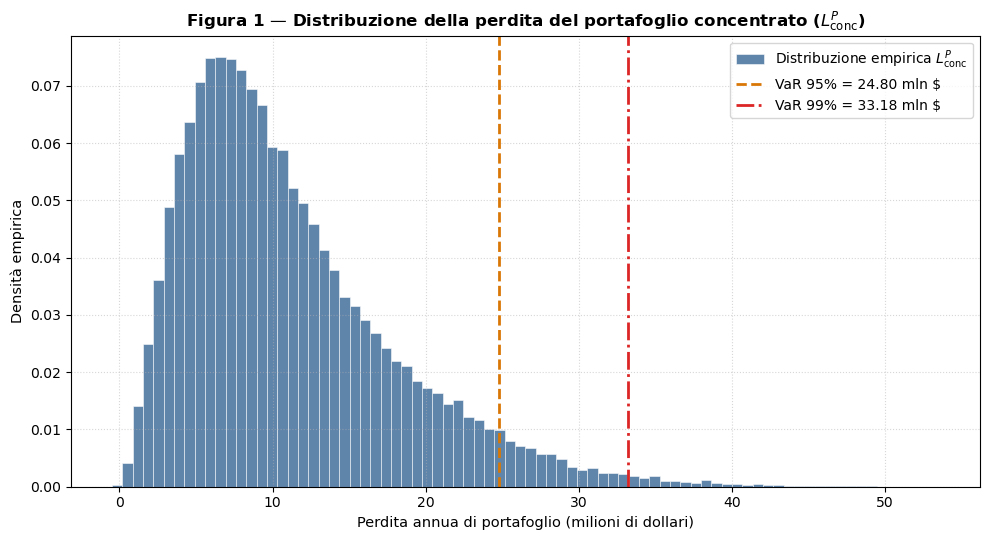

### Riepilogo controlli — Tappa 4

Controllo,Descrizione,Valore verificato,Esito
Controllo 11,I 39 debitori comuni utilizzano esattamente le stesse traiettorie nei due portafogli,Traiettorie identiche (shape 50.000 x 39),SUPERATO
Controllo 12,Perdita totale uguale alla somma delle perdite individuali per entrambi i portafogli,Max diff conc: 0.00e+00 | div: 0.00e+00,SUPERATO
Controllo 14,VaR e CVaR calcolati sulle distribuzioni empiriche delle perdite monetarie (mln $),"Monotonicità e scala in [0, 112.45] mln $ verificate",SUPERATO
Controllo 15,Stabilità delle principali misure di rischio al crescere del numero di repliche,Max var. rel. (40k vs 50k): 0.38%,SUPERATO


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ==============================================================================
# 1. CALCOLO DELLE PERDITE MONETARIE — PORTAFOGLIO CONCENTRATO (40 DEBITORI)
# ==============================================================================
# Associazione deterministica del tasso migration-based phi(X_{i,0}, X_{i,4}^{(r)}):
# poiché phi(r_0, D) = 0.65 = LGD e D è assorbente, la formula incorpora sia
# migrazioni senza default sia eventi di default, in milioni di dollari.
tassi_perdita_conc = PHI[X_0_conc_idx[None, :], X_4_conc_idx]  # shape: (N_MC, 40)
L_ind_conc = tassi_perdita_conc * V_0_conc[None, :]            # shape: (N_MC, 40)
L_conc_P = L_ind_conc.sum(axis=1)                              # shape: (N_MC,)

# ==============================================================================
# 2. CALCOLO DELLE PERDITE MONETARIE — PORTAFOGLIO CONTROFATTUALE (39 DEBITORI)
# ==============================================================================
# Principio delle variabili casuali comuni (Common Random Numbers):
# si estraggono esattamente le traiettorie già simulate dei 39 debitori comuni (i != L),
# senza generare alcuna nuova estrazione pseudocasuale.
X_0_div_idx = X_0_conc_idx[mask_non_lehman]                    # shape: (39,)
X_4_div_idx = X_4_conc_idx[:, mask_non_lehman]                 # shape: (N_MC, 39)

tassi_perdita_div = PHI[X_0_div_idx[None, :], X_4_div_idx]     # shape: (N_MC, 39)
L_ind_div = tassi_perdita_div * V_0_div[None, :]               # shape: (N_MC, 39)
L_div_P = L_ind_div.sum(axis=1)                                # shape: (N_MC,)

# ==============================================================================
# 3. FUNZIONI DI STIMA DELLE MISURE DI RISCHIO (DEFINIZIONE MEDIANTE QUANTILI)
# ==============================================================================
def calcola_var_cvar_quantili(perdite: np.ndarray, alpha: float) -> tuple[float, float]:
    """
    Calcola VaR_alpha e CVaR_alpha secondo la definizione mediante quantili (Cap. 9):
      - VaR_alpha(L) = F_L^{-1}(alpha) (quantile empirico inferiore / order statistic)
      - CVaR_alpha(L) = (1 / (1 - alpha)) * int_alpha^1 q_u(L) du
    Su un campione ordinato L_{(1)} <= ... <= L_{(N)} con alpha * N intero,
    l'integrale dei quantili coincide esattamente con la media delle ultime
    N * (1 - alpha) statistiche d'ordine.
    """
    n = len(perdite)
    perdite_ordinate = np.sort(perdite)
    idx_soglia = int(np.ceil(alpha * n)) - 1
    var_alpha = float(perdite_ordinate[idx_soglia])
    # Integrazione esatta della funzione quantile empirica su [alpha, 1]
    u_grid = np.linspace(alpha, 1.0, num=max(10_000, int(round((1.0 - alpha) * n)) * 10), endpoint=False)
    quantili_coda = np.quantile(perdite_ordinate, u_grid, method="inverted_cdf")
    cvar_alpha = float(np.mean(quantili_coda))
    return var_alpha, cvar_alpha

def calcola_misure_rischio(perdite: np.ndarray) -> dict[str, float]:
    """Restituisce tutte le misure di rischio richieste per un portafoglio (in mln USD)."""
    media = float(np.mean(perdite))
    varianza = float(np.var(perdite, ddof=1))
    dev_std = float(np.std(perdite, ddof=1))
    var_95, cvar_95 = calcola_var_cvar_quantili(perdite, 0.95)
    var_99, cvar_99 = calcola_var_cvar_quantili(perdite, 0.99)
    return {
        "Perdita media": media,
        "Varianza": varianza,
        "Deviazione standard": dev_std,
        "VaR 95%": var_95,
        "CVaR 95%": cvar_95,
        "VaR 99%": var_99,
        "CVaR 99%": cvar_99,
    }

misure_conc = calcola_misure_rischio(L_conc_P)
misure_div = calcola_misure_rischio(L_div_P)

df_misure_tappa4 = pd.DataFrame({
    "Misura di rischio": list(misure_conc.keys()),
    "Portafoglio concentrato (mln $)": list(misure_conc.values()),
    "Portafoglio controfattuale (mln $)": list(misure_div.values()),
})

display(Markdown("### Misure di rischio stimate per entrambi i portafogli ($N_{\\mathrm{MC}} = 50\\,000$, orizzonte 1 anno)"))
display(
    df_misure_tappa4.style
    .format({
        "Portafoglio concentrato (mln $)": "{:,.4f}",
        "Portafoglio controfattuale (mln $)": "{:,.4f}",
    })
    .hide(axis="index")
)

# ==============================================================================
# 4. VERIFICA DI STABILITÀ AL CRESCERE DEL NUMERO DI REPLICHE (CONTROLLO 15)
# ==============================================================================
dimensioni_campione = [5_000, 10_000, 20_000, 30_000, 40_000, 50_000]
righe_stabilita = []

for n_sub in dimensioni_campione:
    m_c = calcola_misure_rischio(L_conc_P[:n_sub])
    m_d = calcola_misure_rischio(L_div_P[:n_sub])
    righe_stabilita.append({
        "Repliche (n)": n_sub,
        "E[L_conc]": m_c["Perdita media"],
        "VaR 95% conc": m_c["VaR 95%"],
        "CVaR 95% conc": m_c["CVaR 95%"],
        "VaR 99% conc": m_c["VaR 99%"],
        "CVaR 99% conc": m_c["CVaR 99%"],
        "E[L_div]": m_d["Perdita media"],
        "VaR 95% div": m_d["VaR 95%"],
        "CVaR 95% div": m_d["CVaR 95%"],
        "VaR 99% div": m_d["VaR 99%"],
        "CVaR 99% div": m_d["CVaR 99%"],
    })

df_stabilita = pd.DataFrame(righe_stabilita)

display(Markdown("### Verifica di stabilità delle misure di rischio al crescere delle repliche simulate (Controllo 15)"))
display(
    df_stabilita.style
    .format({col: "{:,.4f}" for col in df_stabilita.columns if col != "Repliche (n)"})
    .format({"Repliche (n)": "{:,d}"})
    .hide(axis="index")
)

# ==============================================================================
# 5. FIGURA 1 — DISTRIBUZIONE DELLA PERDITA DEL PORTAFOGLIO CONCENTRATO
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.hist(
    L_conc_P,
    bins=80,
    density=True,
    color="#2b5c8f",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.5,
    label="Distribuzione empirica $L_{\\mathrm{conc}}^P$"
)

ax.axvline(
    misure_conc["VaR 95%"],
    color="#d97706",
    linestyle="--",
    linewidth=2.0,
    label=f"VaR 95% = {misure_conc['VaR 95%']:.2f} mln $"
)

ax.axvline(
    misure_conc["VaR 99%"],
    color="#dc2626",
    linestyle="-.",
    linewidth=2.0,
    label=f"VaR 99% = {misure_conc['VaR 99%']:.2f} mln $"
)

ax.set_title("Figura 1 — Distribuzione della perdita del portafoglio concentrato ($L_{\\mathrm{conc}}^P$)", fontsize=12, fontweight="bold")
ax.set_xlabel("Perdita annua di portafoglio (milioni di dollari)", fontsize=10.5)
ax.set_ylabel("Densità empirica", fontsize=10.5)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# ==============================================================================
# 6. ESECUZIONE DEI CONTROLLI DELLA TAPPA 4 (CONTROLLI 11, 12, 14 E 15)
# ==============================================================================
tol = 1e-12

# Controllo 11: utilizzo esatto delle stesse traiettorie creditizie dei 39 debitori comuni
ctrl_11 = bool(
    np.array_equal(X_4_div_idx, X_4_conc_idx[:, mask_non_lehman]) and
    np.array_equal(X_0_div_idx, X_0_conc_idx[mask_non_lehman]) and
    (X_4_div_idx.shape == (N_MC, 39))
)

# Controllo 12: perdita totale di ciascun portafoglio uguale alla somma delle perdite individuali
diff_somma_conc = float(np.max(np.abs(L_conc_P - L_ind_conc.sum(axis=1))))
diff_somma_div = float(np.max(np.abs(L_div_P - L_ind_div.sum(axis=1))))
ctrl_12 = bool((diff_somma_conc <= tol) and (diff_somma_div <= tol))

# Controllo 14: VaR e CVaR calcolati sulle distribuzioni empiriche delle perdite monetarie (mln USD)
# Verifica scala monetaria coerente con V_0 = 173 mln USD e ordinamento teorico E[L] <= VaR95 <= CVaR95 <= VaR99 <= CVaR99
ordine_conc = (
    misure_conc["Perdita media"] <= misure_conc["VaR 95%"] <= misure_conc["CVaR 95%"]
    <= misure_conc["VaR 99%"] <= misure_conc["CVaR 99%"] <= 173.0 * LGD
)
ordine_div = (
    misure_div["Perdita media"] <= misure_div["VaR 95%"] <= misure_div["CVaR 95%"]
    <= misure_div["VaR 99%"] <= misure_div["CVaR 99%"] <= 173.0 * LGD
)
ctrl_14 = bool(ordine_conc and ordine_div)

# Controllo 15: ragionevole stabilità delle misure di rischio al crescere delle repliche
# Confronto relativo tra n = 40_000 e n = 50_000 sulle metriche principali (soglia di stabilità 2%)
metriche_check = ["E[L_conc]", "VaR 95% conc", "CVaR 95% conc", "VaR 99% conc", "CVaR 99% conc",
                  "E[L_div]",  "VaR 95% div",  "CVaR 95% div",  "VaR 99% div",  "CVaR 99% div"]
val_40k = df_stabilita.loc[df_stabilita["Repliche (n)"] == 40_000, metriche_check].to_numpy()[0]
val_50k = df_stabilita.loc[df_stabilita["Repliche (n)"] == 50_000, metriche_check].to_numpy()[0]
max_var_rel = float(np.max(np.abs(val_50k - val_40k) / np.abs(val_50k)))
ctrl_15 = bool(max_var_rel < 0.02)

controlli_tappa_4 = pd.DataFrame([
    {
        "Controllo": "Controllo 11",
        "Descrizione": "I 39 debitori comuni utilizzano esattamente le stesse traiettorie nei due portafogli",
        "Valore verificato": "Traiettorie identiche (shape 50.000 x 39)",
        "Esito": "SUPERATO" if ctrl_11 else "NON SUPERATO"
    },
    {
        "Controllo": "Controllo 12",
        "Descrizione": "Perdita totale uguale alla somma delle perdite individuali per entrambi i portafogli",
        "Valore verificato": f"Max diff conc: {diff_somma_conc:.2e} | div: {diff_somma_div:.2e}",
        "Esito": "SUPERATO" if ctrl_12 else "NON SUPERATO"
    },
    {
        "Controllo": "Controllo 14",
        "Descrizione": "VaR e CVaR calcolati sulle distribuzioni empiriche delle perdite monetarie (mln $)",
        "Valore verificato": f"Monotonicità e scala in [0, {173.0 * LGD:.2f}] mln $ verificate",
        "Esito": "SUPERATO" if ctrl_14 else "NON SUPERATO"
    },
    {
        "Controllo": "Controllo 15",
        "Descrizione": "Stabilità delle principali misure di rischio al crescere del numero di repliche",
        "Valore verificato": f"Max var. rel. (40k vs 50k): {max_var_rel:.2%}",
        "Esito": "SUPERATO" if ctrl_15 else "NON SUPERATO"
    }
])

display(Markdown("### Riepilogo controlli — Tappa 4"))
display(controlli_tappa_4.style.hide(axis="index"))

assert all([ctrl_11, ctrl_12, ctrl_14, ctrl_15]), "Errore nella verifica dei controlli della Tappa 4."

# Tappa 5 — Analisi dell'impatto del regime di crisi ($C$) sul portafoglio concentrato

### Richiesta dello studente

> Sto lavorando sulla Tappa 5.

> **Nota di revisione (Regime C — Criticità accolta):**
> 1. **Criticità individuata:** Mancanza della legenda nel pannello destro (boxplot delle dispersioni) della **Figura 3**, con conseguente ambiguità visiva tra il marker della media condizionata e la linea della mediana.
> 2. **Origine della criticità:** Configurazione di `axes[1].boxplot(...)` priva di un blocco `axes[1].legend(...)` che associasse etichette esplicite a `meanprops` e `medianprops`.
> 3. **Modifica adottata:** Inserimento della legenda nel pannello destro della **Figura 3** per distinguere esplicitamente **Media condizionata** e **Mediana**, mantenendo invariati calcoli, dati, tabelle e controlli.

---

### Sintesi logica della Tappa 5

- **Input:**
  - Matrice degli indici delle traiettorie sistemiche `M_traj_idx` ($50\,000 \times 4$) e mappa degli stati sistemici `SISTEMICO_TO_IDX` (da **Tappa 1** e **Tappa 2**).
  - Vettore delle perdite monetarie simulate del portafoglio concentrato `L_conc_P` ($50\,000 \times 1$, in milioni di dollari) e relativa perdita media incondizionata `misure_conc["Perdita media"]` (da **Tappa 4**).
- **Operazioni:**
  - Definizione dell'evento $E_C = \{\exists\,t \in \{0, 1, 2, 3\} : M_t = C\}$ e del suo evento complementare $E_C^c = \{\forall\,t \in \{0, 1, 2, 3\} : M_t \neq C\}$ mediante indicizzazione booleana sulle traiettorie sistemiche simulate.
  - Stima empirica della probabilità che il regime di crisi $C$ venga raggiunto almeno una volta nell'orizzonte di un anno:

$$
\hat{p}_C = \frac{1}{N_{\mathrm{MC}}} \sum_{r=1}^{N_{\mathrm{MC}}} \mathbf{1}_{\{E_C\}}^{(r)}
$$

  - Partizione del campione simulato $L_{\mathrm{conc}}^{P,(r)}$ nei due sottoinsiemi condizionati ($E_C$ ed $E_C^c$) e calcolo delle perdite medie condizionate $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C]$ e $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C^c]$, unitamente alle principali statistiche descrittive condizionate.
  - Costruzione della **Tabella 4 — Regime sistemico e perdita**, produzione della **Figura 3 — Regime sistemico e perdita** ed esecuzione dei controlli logici e numerici della tappa.
- **Output:**
  - Probabilità simulata $\hat{p}_C$ di ingresso almeno una volta nel regime $C$.
  - Perdite medie condizionate del portafoglio concentrato nelle repliche con ingresso in $C$ ($\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C]$) e senza ingresso in $C$ ($\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C^c]$).
  - **Tabella 4 — Regime sistemico e perdita** (confronto per il portafoglio concentrato tra repliche con e senza ingresso nello stato $C$).
  - **Figura 3 — Regime sistemico e perdita** (confronto grafico delle perdite del portafoglio concentrato tra repliche in cui lo stato $C$ viene raggiunto almeno una volta e repliche in cui non viene mai raggiunto).
  - Tabella riepilogativa di verifica dei controlli della Tappa 5.
- **Controlli della tappa:**
  - Verifica logica della partizione esaustiva e disgiunta delle $N_{\mathrm{MC}} = 50\,000$ repliche ($N_{E_C} + N_{E_C^c} = N_{\mathrm{MC}}$ e $E_C \cap E_C^c = \emptyset$).
  - Verifica di coerenza con la legge delle aspettative totali: $\hat{p}_C\,\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C] + (1 - \hat{p}_C)\,\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C^c] = \widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$.
  - Verifica della coerenza con la condizione iniziale $M_0 = S$ (nessun ingresso in $C$ al tempo $t = 0$).
- **Uso dell'output nella tappa successiva o nel prodotto finale:**
  - Fornisce **Tabella 4**, **Figura 3** e le stime numeriche sul ruolo del regime sistemico di crisi direttamente al prodotto finale per la successiva **Fase 8 — Interpretazione finale** dello studente.

### Tabella 4 — Regime sistemico e perdita (portafoglio concentrato)

Scenario sistemico,Numero repliche,Probabilità stimata,Perdita media (mln $),Deviazione standard (mln $),Mediana (mln $),Quantile 95% (mln $)
Regime C raggiunto almeno una volta (E_C),"14,848",29.70%,18.3169,6.7957,17.4300,30.8865
Regime C mai raggiunto (E_C^c),"35,152",70.30%,8.0775,4.2429,7.4900,15.5200
Portafoglio concentrato complessivo (Incondizionato),"50,000",100.00%,11.1182,6.9469,9.5100,24.8000


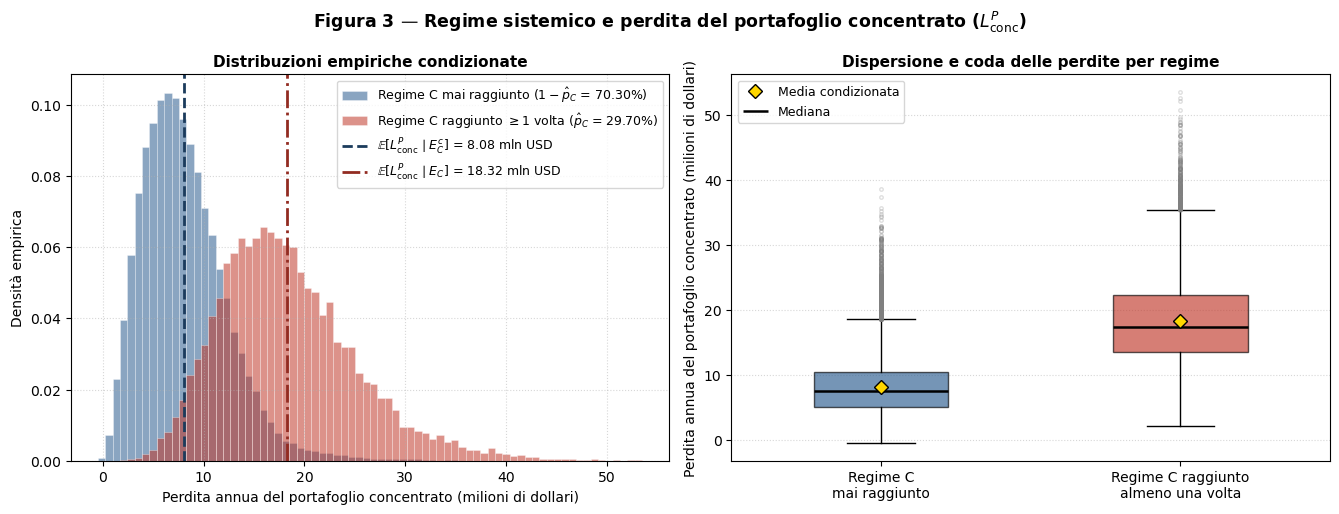

### Riepilogo controlli — Tappa 5

Controllo,Descrizione,Valore verificato,Esito
"Partizione campionaria (E_C, E_C^c)",Partizione esaustiva e disgiunta delle N_MC = 50.000 repliche,"14,848 + 35,152 = 50,000 (p_C + p_C^c = 1.000000)",SUPERATO
Legge delle aspettative totali,Coerenza tra medie condizionate e media incondizionata E[L_conc^P],Diff. assoluta: 1.78e-15,SUPERATO
Coerenza stato iniziale M_0 = S,Assenza dello stato di crisi C al trimestre iniziale t = 0,Repliche con M_0 = C: 0,SUPERATO


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ==============================================================================
# 1. IDENTIFICAZIONE DELL'EVENTO E_C (INGRESSO ALMENO UNA VOLTA NEL REGIME C)
# ==============================================================================
idx_crisi = SISTEMICO_TO_IDX["C"]  # indice 2

# Maschera booleana per replica r: True se M_t^{(r)} == C per almeno un t in {0, 1, 2, 3}
evento_C = np.any(M_traj_idx == idx_crisi, axis=1)
evento_no_C = ~evento_C

n_con_C = int(np.sum(evento_C))
n_senza_C = int(np.sum(evento_no_C))

# Probabilità empirica di raggiungere il regime C almeno una volta
prob_C = float(np.mean(evento_C))
prob_no_C = float(np.mean(evento_no_C))

# ==============================================================================
# 2. PERDITE DEL PORTAFOGLIO CONCENTRATO CONDIZIONATE AL REGIME SISTEMICO
# ==============================================================================
L_conc_con_C = L_conc_P[evento_C]
L_conc_senza_C = L_conc_P[evento_no_C]

media_L_conc_con_C = float(np.mean(L_conc_con_C))
media_L_conc_senza_C = float(np.mean(L_conc_senza_C))

std_L_conc_con_C = float(np.std(L_conc_con_C, ddof=1))
std_L_conc_senza_C = float(np.std(L_conc_senza_C, ddof=1))

mediana_L_conc_con_C = float(np.median(L_conc_con_C))
mediana_L_conc_senza_C = float(np.median(L_conc_senza_C))

q95_L_conc_con_C = float(np.quantile(L_conc_con_C, 0.95))
q95_L_conc_senza_C = float(np.quantile(L_conc_senza_C, 0.95))

# ==============================================================================
# 3. TABELLA 4 — REGIME SISTEMICO E PERDITA (PORTAFOGLIO CONCENTRATO)
# ==============================================================================
tabella_4 = pd.DataFrame([
    {
        "Scenario sistemico": "Regime C raggiunto almeno una volta (E_C)",
        "Numero repliche": n_con_C,
        "Probabilità stimata": prob_C,
        "Perdita media (mln $)": media_L_conc_con_C,
        "Deviazione standard (mln $)": std_L_conc_con_C,
        "Mediana (mln $)": mediana_L_conc_con_C,
        "Quantile 95% (mln $)": q95_L_conc_con_C,
    },
    {
        "Scenario sistemico": "Regime C mai raggiunto (E_C^c)",
        "Numero repliche": n_senza_C,
        "Probabilità stimata": prob_no_C,
        "Perdita media (mln $)": media_L_conc_senza_C,
        "Deviazione standard (mln $)": std_L_conc_senza_C,
        "Mediana (mln $)": mediana_L_conc_senza_C,
        "Quantile 95% (mln $)": q95_L_conc_senza_C,
    },
    {
        "Scenario sistemico": "Portafoglio concentrato complessivo (Incondizionato)",
        "Numero repliche": int(N_MC),
        "Probabilità stimata": 1.0,
        "Perdita media (mln $)": misure_conc["Perdita media"],
        "Deviazione standard (mln $)": misure_conc["Deviazione standard"],
        "Mediana (mln $)": float(np.median(L_conc_P)),
        "Quantile 95% (mln $)": misure_conc["VaR 95%"],
    }
])

display(Markdown("### Tabella 4 — Regime sistemico e perdita (portafoglio concentrato)"))
display(
    tabella_4.style
    .format({
        "Numero repliche": "{:,d}",
        "Probabilità stimata": "{:.2%}",
        "Perdita media (mln $)": "{:,.4f}",
        "Deviazione standard (mln $)": "{:,.4f}",
        "Mediana (mln $)": "{:,.4f}",
        "Quantile 95% (mln $)": "{:,.4f}",
    })
    .hide(axis="index")
)

# ==============================================================================
# 4. FIGURA 3 — REGIME SISTEMICO E PERDITA (PORTAFOGLIO CONCENTRATO)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

bins_comuni = np.linspace(float(np.min(L_conc_P)), float(np.max(L_conc_P)), 75)

# Pannello sinistro: distribuzioni empiriche sovrapposte e medie condizionate
axes[0].hist(
    L_conc_senza_C,
    bins=bins_comuni,
    density=True,
    color="#2b5c8f",
    alpha=0.55,
    edgecolor="white",
    linewidth=0.4,
    label=f"Regime C mai raggiunto ($1 - \\hat{{p}}_C$ = {prob_no_C:.2%})"
)
axes[0].hist(
    L_conc_con_C,
    bins=bins_comuni,
    density=True,
    color="#c0392b",
    alpha=0.55,
    edgecolor="white",
    linewidth=0.4,
    label=f"Regime C raggiunto $\\geq 1$ volta ($\\hat{{p}}_C$ = {prob_C:.2%})"
)

axes[0].axvline(
    media_L_conc_senza_C,
    color="#1b3b5c",
    linestyle="--",
    linewidth=2.0,
    label=f"$\\mathbb{{E}}[L_{{\\mathrm{{conc}}}}^P \\mid E_C^c]$ = {media_L_conc_senza_C:.2f} mln USD"
)
axes[0].axvline(
    media_L_conc_con_C,
    color="#922b21",
    linestyle="-.",
    linewidth=2.0,
    label=f"$\\mathbb{{E}}[L_{{\\mathrm{{conc}}}}^P \\mid E_C]$ = {media_L_conc_con_C:.2f} mln USD"
)

axes[0].set_title("Distribuzioni empiriche condizionate", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Perdita annua del portafoglio concentrato (milioni di dollari)", fontsize=10)
axes[0].set_ylabel("Densità empirica", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.5)
axes[0].legend(frameon=True, fontsize=9)

# Pannello destro: boxplot comparativo con indicazione e legenda di media e mediana
bp = axes[1].boxplot(
    [L_conc_senza_C, L_conc_con_C],
    tick_labels=["Regime C\nmai raggiunto", "Regime C raggiunto\nalmeno una volta"],
    patch_artist=True,
    widths=0.45,
    showmeans=True,
    meanprops=dict(marker="D", markeredgecolor="black", markerfacecolor="gold", markersize=7, zorder=4),
    medianprops=dict(color="black", linewidth=1.8, zorder=3),
    flierprops=dict(marker="o", markersize=2.5, alpha=0.25, markeredgecolor="gray")
)

colori_box = ["#2b5c8f", "#c0392b"]
for patch, colore in zip(bp["boxes"], colori_box):
    patch.set_facecolor(colore)
    patch.set_alpha(0.65)

axes[1].legend(
    handles=[bp["means"][0], bp["medians"][0]],
    labels=["Media condizionata", "Mediana"],
    frameon=True,
    fontsize=9,
    loc="upper left"
)

axes[1].set_title("Dispersione e coda delle perdite per regime", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Perdita annua del portafoglio concentrato (milioni di dollari)", fontsize=10)
axes[1].grid(True, axis="y", linestyle=":", alpha=0.5)

fig.suptitle(
    "Figura 3 — Regime sistemico e perdita del portafoglio concentrato ($L_{\\mathrm{conc}}^P$)",
    fontsize=12.5,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 5. ESECUZIONE DEI CONTROLLI DELLA TAPPA 5
# ==============================================================================
tol = 1e-12

# Controllo 5.1: partizione esaustiva e disgiunta delle N_MC = 50_000 repliche
ctrl_partizione = bool(
    (n_con_C + n_senza_C == N_MC) and
    np.all(evento_C | evento_no_C) and
    (not np.any(evento_C & evento_no_C)) and
    np.isclose(prob_C + prob_no_C, 1.0, atol=tol)
)

# Controllo 5.2: legge delle aspettative totali sulla perdita media del portafoglio concentrato
media_ricostruita = prob_C * media_L_conc_con_C + prob_no_C * media_L_conc_senza_C
diff_media_totale = abs(media_ricostruita - misure_conc["Perdita media"])
ctrl_aspettative_totali = bool(diff_media_totale <= tol)

# Controllo 5.3: coerenza con lo stato iniziale deterministico M_0 = S (nessun C a t = 0)
n_C_a_t0 = int(np.sum(M_traj_idx[:, 0] == idx_crisi))
ctrl_t0_no_C = (n_C_a_t0 == 0)

controlli_tappa_5 = pd.DataFrame([
    {
        "Controllo": "Partizione campionaria (E_C, E_C^c)",
        "Descrizione": "Partizione esaustiva e disgiunta delle N_MC = 50.000 repliche",
        "Valore verificato": f"{n_con_C:,d} + {n_senza_C:,d} = {n_con_C + n_senza_C:,d} (p_C + p_C^c = {prob_C + prob_no_C:.6f})",
        "Esito": "SUPERATO" if ctrl_partizione else "NON SUPERATO"
    },
    {
        "Controllo": "Legge delle aspettative totali",
        "Descrizione": "Coerenza tra medie condizionate e media incondizionata E[L_conc^P]",
        "Valore verificato": f"Diff. assoluta: {diff_media_totale:.2e}",
        "Esito": "SUPERATO" if ctrl_aspettative_totali else "NON SUPERATO"
    },
    {
        "Controllo": "Coerenza stato iniziale M_0 = S",
        "Descrizione": "Assenza dello stato di crisi C al trimestre iniziale t = 0",
        "Valore verificato": f"Repliche con M_0 = C: {n_C_a_t0}",
        "Esito": "SUPERATO" if ctrl_t0_no_C else "NON SUPERATO"
    }
])

display(Markdown("### Riepilogo controlli — Tappa 5"))
display(controlli_tappa_5.style.hide(axis="index"))

assert all([ctrl_partizione, ctrl_aspettative_totali, ctrl_t0_no_C]), (
    "Errore nella verifica dei controlli della Tappa 5."
)

# Tappa 6 — Confronto differenziale tra i portafogli e sintesi finale

### Richiesta dello studente

> Sto lavorando sulla Tappa 6.

> **Nota di revisione (Regime C — Criticità accolta):**
> 1. **Criticità individuata:** Codifica cromatica e stile delle linee dei quantili nella **Figura 2** non conformi alle specifiche visive richieste per il confronto tra i due portafogli.
> 2. **Origine della criticità:** Scelta stilistica nella costruzione di `axes[0]` e `axes[1]` della **Figura 2** (uso di blu/verde per gli istogrammi e tratto `-.` per il $\operatorname{VaR}_{0.99}$).
> 3. **Modifica adottata:** Impostazione in entrambi i pannelli della **Figura 2** del colore **rosso** (con trasparenza) per $L_{\mathrm{conc}}^P$ e **giallo** (con trasparenza) per $L_{\mathrm{div}}^P$, abbinati a linee **tratteggiate** (`--`) rosse/gialle per il $\operatorname{VaR}_{0.95}$ e linee **continue** (`-`) rosse/gialle per il $\operatorname{VaR}_{0.99}$, lasciando invariati dati, formule, tabelle e controlli.

---

### Sintesi logica della Tappa 6

- **Input:**
  - Vettori delle perdite annue simulate (in milioni di dollari) del portafoglio concentrato `L_conc_P` e del portafoglio controfattuale `L_div_P` ($50\,000 \times 1$) (da **Tappa 4**).
  - Dizionari delle misure di rischio stimate `misure_conc` e `misure_div` (perdita media, varianza, deviazione standard, $\operatorname{VaR}_{0.95}$, $\operatorname{CVaR}_{0.95}$, $\operatorname{VaR}_{0.99}$, $\operatorname{CVaR}_{0.99}$) (da **Tappa 4**).
  - Indicatori booleani di verifica dei controlli strutturali, logici e computazionali prodotti nelle **Tappe 1–5**.
- **Operazioni:**
  - Calcolo delle variazioni delle misure di rischio $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$ per ciascuna metrica $\rho$ e composizione della **Tabella 3 — Misure di rischio**.
  - Calcolo della differenza accoppiata replica per replica $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ ($r = 1, \dots, N_{\mathrm{MC}}$) e caratterizzazione numerica della sua distribuzione empirica $\hat{F}_{\Delta L}$ (momenti, quantili principali e frequenze di segno).
  - Tracciamento della **Figura 2 — Confronto delle distribuzioni** mediante confronto diretto tra le distribuzioni empiriche di $L_{\mathrm{conc}}^P$ (rosso trasparente) e $L_{\mathrm{div}}^P$ (giallo trasparente) sull'intero supporto e ingrandimento sulla coda destra, con indicazione di $\operatorname{VaR}_{0.95}$ (linee tratteggiate) e $\operatorname{VaR}_{0.99}$ (linee continue).
  - Esecuzione del controllo di linearità del valore atteso sulla differenza accoppiata e compilazione del riepilogo complessivo dei **Controlli 1–15** previsti dalla Scheda Caso.
- **Output:**
  - **Tabella 3 — Misure di rischio** (confronto tra portafoglio concentrato, portafoglio con riallocazione proporzionale e differenza $\Delta\rho$).
  - Tabella descrittiva della distribuzione empirica di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$.
  - **Figura 2 — Confronto delle distribuzioni** (confronto tra le distribuzioni empiriche delle perdite dei due portafogli con dettaglio sulla coda destra).
  - Tabella di verifica dei controlli della Tappa 6 e quadro riepilogativo finale dei **Controlli 1–15**.
- **Controlli della tappa:**
  - Verifica di coerenza lineare del valore atteso: $\widehat{\mathbb{E}}[\Delta L] = \widehat{\mathbb{E}}[L_{\mathrm{div}}^P] - \widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$.
  - Verifica dell'allineamento dimensionale ($N_{\mathrm{MC}} = 50\,000$ repliche accoppiate) e della conservazione dell'investimento complessivo ($173$ milioni di dollari) nel confronto differenziale.
  - Riepilogo integrale e verifica finale dei **Controlli 1–15** della Scheda Caso.
- **Uso dell'output nella tappa successiva o nel prodotto finale:**
  - Completa la **Fase 7 — Costruzione progressiva del notebook** e fornisce l'intero apparato quantitativo, tabellare e grafico validato per la **Fase 8 — Interpretazione finale** autonoma dello studente.

### Tabella 3 — Misure di rischio (milioni di dollari; varianza in mln USD$^2$)

Misura di rischio,Portafoglio concentrato,Portafoglio controfattuale,Differenza (Delta rho),Variazione relativa
Perdita media,11.1182,12.1877,+1.0696,+9.62%
Varianza,48.2596,53.3336,+5.0740,+10.51%
Deviazione standard,6.9469,7.3030,+0.3561,+5.13%
VaR 95%,24.8000,26.6163,+1.8163,+7.32%
CVaR 95%,29.8047,31.0662,+1.2615,+4.23%
VaR 99%,33.1800,33.8636,+0.6836,+2.06%
CVaR 99%,37.4234,37.3024,-0.1210,-0.32%


### Distribuzione empirica di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$

Statistica di Delta L^(r) = L_div - L_conc,Valore
Media empirica (mln USD),1.0696
Deviazione standard (mln USD),2.3650
Minimo (mln USD),-16.0676
Quantile 1% (mln USD),-13.5557
Quantile 5% (mln USD),-1.4832
Quantile 25% (mln USD),0.6520
Mediana / Quantile 50% (mln USD),1.2584
Quantile 75% (mln USD),2.0118
Quantile 95% (mln USD),3.4966
Quantile 99% (mln USD),4.5997


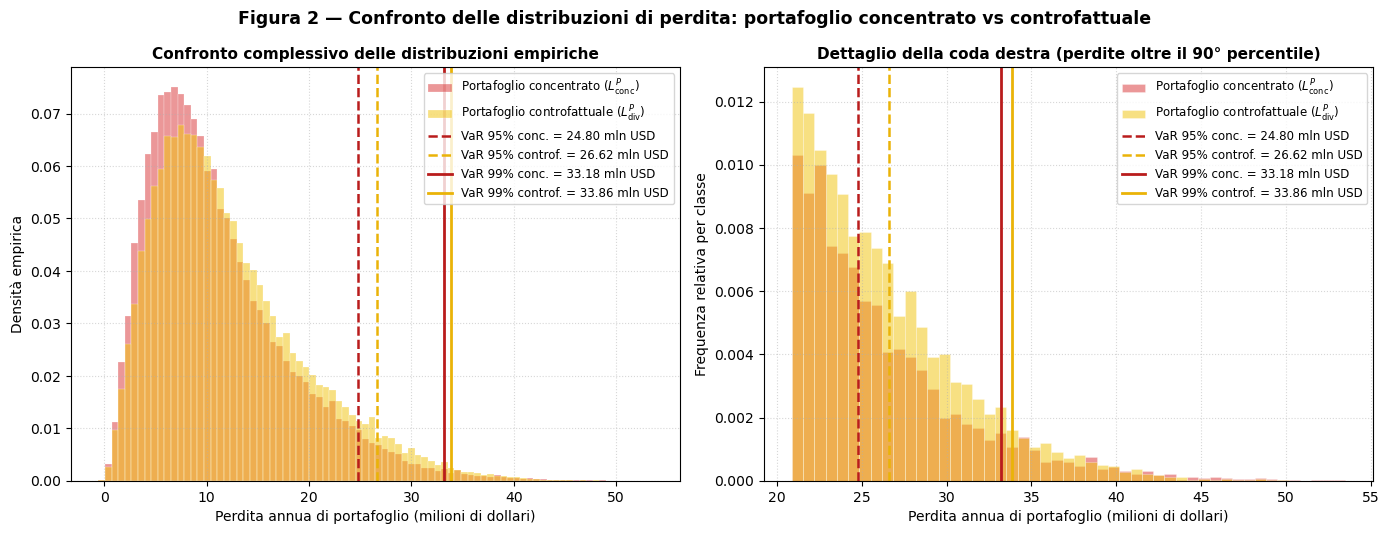

### Riepilogo controlli specifici — Tappa 6

Controllo,Descrizione,Valore verificato,Esito
Linearità valore atteso Delta L,Coerenza E[Delta L^(r)] = E[L_div^P] - E[L_conc^P],Diff. assoluta: 1.33e-15,SUPERATO
Integrità campionaria Delta L^(r),"Dimensione (50.000,) e assenza di valori NaN/Inf nelle differenze accoppiate","Shape: (50000,)",SUPERATO


### Quadro riepilogativo generale — Controlli 1–15 della Scheda Caso

ID,Categoria,Tappa,Descrizione,Esito
Controllo 1,Numerico,Tappa 1,Ogni riga della matrice Q somma a 1,SUPERATO
Controllo 2,Numerico,Tappa 1,"Ogni riga delle matrici P^(O), P^(S) e P^(C) somma a 1",SUPERATO
Controllo 3,Logico/Teorico,"Tappa 1, Tappa 3",Stato D assorbente in tutte le matrici e nelle traiettorie simulate,SUPERATO
Controllo 4,Logico/Teorico,"Tappa 2, Tappa 3","Tutti gli stati simulati appartengono a M = {O,S,C} e I = {A,BBB,BB,B,D}",SUPERATO
Controllo 5,Logico/Teorico,Tappa 2,Unica traiettoria sistemica comune a tutti i debitori in ciascuna replica,SUPERATO
Controllo 6,Logico/Teorico,Tappa 3,Estrazioni casuali individuali indipendenti condizionatamente al regime,SUPERATO
Controllo 7,Numerico,Tappa 1,Portafoglio concentrato composto esattamente da 40 debitori,SUPERATO
Controllo 8,Numerico,Tappa 1,Portafoglio controfattuale composto esattamente da 39 debitori,SUPERATO
Controllo 9,Numerico,Tappa 1,Investimento iniziale complessivo pari a 173 mln USD in entrambi i portafogli,SUPERATO
Controllo 10,Numerico,Tappa 1,Proporzioni relative dei 39 debitori residui inalterate dopo riallocazione,SUPERATO


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ==============================================================================
# 1. CALCOLO DEI DIFFERENZIALI TRA MISURE DI RISCHIO E TABELLA 3
# ==============================================================================
nomi_misure = list(misure_conc.keys())

righe_tabella_3 = []
for m in nomi_misure:
    val_conc = misure_conc[m]
    val_div = misure_div[m]
    delta_rho = val_div - val_conc
    var_rel_pct = (delta_rho / abs(val_conc)) if val_conc != 0.0 else np.nan
    righe_tabella_3.append({
        "Misura di rischio": m,
        "Portafoglio concentrato": val_conc,
        "Portafoglio controfattuale": val_div,
        "Differenza (Delta rho)": delta_rho,
        "Variazione relativa": var_rel_pct,
    })

tabella_3 = pd.DataFrame(righe_tabella_3)

display(Markdown("### Tabella 3 — Misure di rischio (milioni di dollari; varianza in mln USD$^2$)"))
display(
    tabella_3.style
    .format({
        "Portafoglio concentrato": "{:,.4f}",
        "Portafoglio controfattuale": "{:,.4f}",
        "Differenza (Delta rho)": "{:+,.4f}",
        "Variazione relativa": "{:+.2%}",
    })
    .hide(axis="index")
)

# ==============================================================================
# 2. DISTRIBUZIONE EMPIRICA DELLA DIFFERENZA REPLICA PER REPLICA (Delta L^(r))
# ==============================================================================
# Delta L^{(r)} = L_{div}^{P,(r)} - L_{conc}^{P,(r)}
delta_L = L_div_P - L_conc_P

riepilogo_delta_L = pd.DataFrame([
    {"Statistica di Delta L^(r) = L_div - L_conc": "Media empirica (mln USD)",         "Valore": float(np.mean(delta_L))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Deviazione standard (mln USD)",    "Valore": float(np.std(delta_L, ddof=1))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Minimo (mln USD)",                 "Valore": float(np.min(delta_L))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Quantile 1% (mln USD)",            "Valore": float(np.quantile(delta_L, 0.01))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Quantile 5% (mln USD)",            "Valore": float(np.quantile(delta_L, 0.05))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Quantile 25% (mln USD)",           "Valore": float(np.quantile(delta_L, 0.25))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Mediana / Quantile 50% (mln USD)", "Valore": float(np.median(delta_L))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Quantile 75% (mln USD)",           "Valore": float(np.quantile(delta_L, 0.75))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Quantile 95% (mln USD)",           "Valore": float(np.quantile(delta_L, 0.95))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Quantile 99% (mln USD)",           "Valore": float(np.quantile(delta_L, 0.99))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Massimo (mln USD)",                "Valore": float(np.max(delta_L))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Frequenza P(Delta L < 0)",         "Valore": float(np.mean(delta_L < 0.0))},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Frequenza P(Delta L = 0)",         "Valore": float(np.isclose(delta_L, 0.0, atol=1e-12).mean())},
    {"Statistica di Delta L^(r) = L_div - L_conc": "Frequenza P(Delta L > 0)",         "Valore": float(np.mean(delta_L > 0.0))},
])

display(Markdown("### Distribuzione empirica di $\\Delta L^{(r)} = L_{\\mathrm{div}}^{P,(r)} - L_{\\mathrm{conc}}^{P,(r)}$"))
display(
    riepilogo_delta_L.style
    .format({"Valore": "{:,.4f}"})
    .hide(axis="index")
)

# ==============================================================================
# 3. FIGURA 2 — CONFRONTO DELLE DISTRIBUZIONI (INTERO SUPPORTO E CODA DESTRA)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.4))

min_loss = float(min(np.min(L_conc_P), np.min(L_div_P)))
max_loss = float(max(np.max(L_conc_P), np.max(L_div_P)))
bins_full = np.linspace(min_loss, max_loss, 85)

# Palette cromatica richiesta: rosso per concentrato, giallo per controfattuale
colore_hist_conc = "#d62728"   # rosso
colore_hist_div = "#f1c40f"    # giallo
colore_linea_conc = "#b91c1c"  # rosso intenso per le soglie VaR
colore_linea_div = "#eab308"   # giallo intenso per le soglie VaR

# Pannello sinistro: confronto sull'intero supporto delle perdite
axes[0].hist(
    L_conc_P,
    bins=bins_full,
    density=True,
    color=colore_hist_conc,
    alpha=0.48,
    edgecolor="white",
    linewidth=0.35,
    label="Portafoglio concentrato ($L_{\\mathrm{conc}}^P$)"
)
axes[0].hist(
    L_div_P,
    bins=bins_full,
    density=True,
    color=colore_hist_div,
    alpha=0.52,
    edgecolor="white",
    linewidth=0.35,
    label="Portafoglio controfattuale ($L_{\\mathrm{div}}^P$)"
)

axes[0].axvline(
    misure_conc["VaR 95%"],
    color=colore_linea_conc,
    linestyle="--",
    linewidth=1.8,
    label=f"VaR 95% conc. = {misure_conc['VaR 95%']:.2f} mln USD"
)
axes[0].axvline(
    misure_div["VaR 95%"],
    color=colore_linea_div,
    linestyle="--",
    linewidth=1.8,
    label=f"VaR 95% controf. = {misure_div['VaR 95%']:.2f} mln USD"
)
axes[0].axvline(
    misure_conc["VaR 99%"],
    color=colore_linea_conc,
    linestyle="-",
    linewidth=2.0,
    label=f"VaR 99% conc. = {misure_conc['VaR 99%']:.2f} mln USD"
)
axes[0].axvline(
    misure_div["VaR 99%"],
    color=colore_linea_div,
    linestyle="-",
    linewidth=2.0,
    label=f"VaR 99% controf. = {misure_div['VaR 99%']:.2f} mln USD"
)

axes[0].set_title("Confronto complessivo delle distribuzioni empiriche", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Perdita annua di portafoglio (milioni di dollari)", fontsize=10)
axes[0].set_ylabel("Densità empirica", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.5)
axes[0].legend(frameon=True, fontsize=8.5, loc="upper right")

# Pannello destro: ingrandimento sulla coda destra (oltre il 90° percentile)
soglia_coda = float(min(np.quantile(L_conc_P, 0.90), np.quantile(L_div_P, 0.90)))
bins_coda = np.linspace(soglia_coda, max_loss, 50)

axes[1].hist(
    L_conc_P[L_conc_P >= soglia_coda],
    bins=bins_coda,
    density=False,
    weights=np.ones(np.sum(L_conc_P >= soglia_coda)) / N_MC,
    color=colore_hist_conc,
    alpha=0.48,
    edgecolor="white",
    linewidth=0.4,
    label="Portafoglio concentrato ($L_{\\mathrm{conc}}^P$)"
)
axes[1].hist(
    L_div_P[L_div_P >= soglia_coda],
    bins=bins_coda,
    density=False,
    weights=np.ones(np.sum(L_div_P >= soglia_coda)) / N_MC,
    color=colore_hist_div,
    alpha=0.52,
    edgecolor="white",
    linewidth=0.4,
    label="Portafoglio controfattuale ($L_{\\mathrm{div}}^P$)"
)

axes[1].axvline(
    misure_conc["VaR 95%"],
    color=colore_linea_conc,
    linestyle="--",
    linewidth=1.8,
    label=f"VaR 95% conc. = {misure_conc['VaR 95%']:.2f} mln USD"
)
axes[1].axvline(
    misure_div["VaR 95%"],
    color=colore_linea_div,
    linestyle="--",
    linewidth=1.8,
    label=f"VaR 95% controf. = {misure_div['VaR 95%']:.2f} mln USD"
)
axes[1].axvline(
    misure_conc["VaR 99%"],
    color=colore_linea_conc,
    linestyle="-",
    linewidth=2.0,
    label=f"VaR 99% conc. = {misure_conc['VaR 99%']:.2f} mln USD"
)
axes[1].axvline(
    misure_div["VaR 99%"],
    color=colore_linea_div,
    linestyle="-",
    linewidth=2.0,
    label=f"VaR 99% controf. = {misure_div['VaR 99%']:.2f} mln USD"
)

axes[1].set_title("Dettaglio della coda destra (perdite oltre il 90° percentile)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Perdita annua di portafoglio (milioni di dollari)", fontsize=10)
axes[1].set_ylabel("Frequenza relativa per classe", fontsize=10)
axes[1].grid(True, linestyle=":", alpha=0.5)
axes[1].legend(frameon=True, fontsize=8.5, loc="upper right")

fig.suptitle(
    "Figura 2 — Confronto delle distribuzioni di perdita: portafoglio concentrato vs controfattuale",
    fontsize=12.5,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. ESECUZIONE DEI CONTROLLI DELLA TAPPA 6 E RIEPILOGO GENERALE CONTROLLI 1–15
# ==============================================================================
tol = 1e-12

# Controllo 6.1: linearità della media E[Delta L] = E[L_div^P] - E[L_conc^P]
diff_linearita_media = abs(float(np.mean(delta_L)) - (misure_div["Perdita media"] - misure_conc["Perdita media"]))
ctrl_linearita_delta = bool(diff_linearita_media <= tol)

# Controllo 6.2: coerenza dimensionale del vettore accoppiato Delta L^(r)
ctrl_dim_delta = bool((delta_L.shape == (N_MC,)) and np.all(np.isfinite(delta_L)))

controlli_tappa_6 = pd.DataFrame([
    {
        "Controllo": "Linearità valore atteso Delta L",
        "Descrizione": "Coerenza E[Delta L^(r)] = E[L_div^P] - E[L_conc^P]",
        "Valore verificato": f"Diff. assoluta: {diff_linearita_media:.2e}",
        "Esito": "SUPERATO" if ctrl_linearita_delta else "NON SUPERATO"
    },
    {
        "Controllo": "Integrità campionaria Delta L^(r)",
        "Descrizione": "Dimensione (50.000,) e assenza di valori NaN/Inf nelle differenze accoppiate",
        "Valore verificato": f"Shape: {delta_L.shape}",
        "Esito": "SUPERATO" if ctrl_dim_delta else "NON SUPERATO"
    }
])

display(Markdown("### Riepilogo controlli specifici — Tappa 6"))
display(controlli_tappa_6.style.hide(axis="index"))

# Consolidamento completo dei 15 controlli previsti dalla Sezione 7 della Scheda Caso
ctrl_3_globale = bool(ctrl_3 and ctrl_3_traj)
ctrl_4_globale = bool(ctrl_4_sist and ctrl_4_cred)

riepilogo_15_controlli = pd.DataFrame([
    {"ID": "Controllo 1",  "Categoria": "Numerico",       "Tappa": "Tappa 1",          "Descrizione": "Ogni riga della matrice Q somma a 1",                                       "Esito": "SUPERATO" if ctrl_1 else "NON SUPERATO"},
    {"ID": "Controllo 2",  "Categoria": "Numerico",       "Tappa": "Tappa 1",          "Descrizione": "Ogni riga delle matrici P^(O), P^(S) e P^(C) somma a 1",                     "Esito": "SUPERATO" if ctrl_2 else "NON SUPERATO"},
    {"ID": "Controllo 3",  "Categoria": "Logico/Teorico", "Tappa": "Tappa 1, Tappa 3", "Descrizione": "Stato D assorbente in tutte le matrici e nelle traiettorie simulate",       "Esito": "SUPERATO" if ctrl_3_globale else "NON SUPERATO"},
    {"ID": "Controllo 4",  "Categoria": "Logico/Teorico", "Tappa": "Tappa 2, Tappa 3", "Descrizione": "Tutti gli stati simulati appartengono a M = {O,S,C} e I = {A,BBB,BB,B,D}",   "Esito": "SUPERATO" if ctrl_4_globale else "NON SUPERATO"},
    {"ID": "Controllo 5",  "Categoria": "Logico/Teorico", "Tappa": "Tappa 2",          "Descrizione": "Unica traiettoria sistemica comune a tutti i debitori in ciascuna replica",   "Esito": "SUPERATO" if ctrl_5 else "NON SUPERATO"},
    {"ID": "Controllo 6",  "Categoria": "Logico/Teorico", "Tappa": "Tappa 3",          "Descrizione": "Estrazioni casuali individuali indipendenti condizionatamente al regime",    "Esito": "SUPERATO" if ctrl_6 else "NON SUPERATO"},
    {"ID": "Controllo 7",  "Categoria": "Numerico",       "Tappa": "Tappa 1",          "Descrizione": "Portafoglio concentrato composto esattamente da 40 debitori",                 "Esito": "SUPERATO" if ctrl_7 else "NON SUPERATO"},
    {"ID": "Controllo 8",  "Categoria": "Numerico",       "Tappa": "Tappa 1",          "Descrizione": "Portafoglio controfattuale composto esattamente da 39 debitori",              "Esito": "SUPERATO" if ctrl_8 else "NON SUPERATO"},
    {"ID": "Controllo 9",  "Categoria": "Numerico",       "Tappa": "Tappa 1",          "Descrizione": "Investimento iniziale complessivo pari a 173 mln USD in entrambi i portafogli","Esito": "SUPERATO" if ctrl_9 else "NON SUPERATO"},
    {"ID": "Controllo 10", "Categoria": "Numerico",       "Tappa": "Tappa 1",          "Descrizione": "Proporzioni relative dei 39 debitori residui inalterate dopo riallocazione",   "Esito": "SUPERATO" if ctrl_10 else "NON SUPERATO"},
    {"ID": "Controllo 11", "Categoria": "Computazionale", "Tappa": "Tappa 4",          "Descrizione": "I 39 debitori comuni utilizzano le stesse traiettorie nei due portafogli",    "Esito": "SUPERATO" if ctrl_11 else "NON SUPERATO"},
    {"ID": "Controllo 12", "Categoria": "Numerico",       "Tappa": "Tappa 4",          "Descrizione": "Perdita totale di ciascun portafoglio uguale alla somma delle perdite indiv.","Esito": "SUPERATO" if ctrl_12 else "NON SUPERATO"},
    {"ID": "Controllo 13", "Categoria": "Computazionale", "Tappa": "Tappa 1–3",        "Descrizione": "Seed = 2026 impostato correttamente per la riproducibilità della simulazione", "Esito": "SUPERATO" if ctrl_13 else "NON SUPERATO"},
    {"ID": "Controllo 14", "Categoria": "Numerico",       "Tappa": "Tappa 4",          "Descrizione": "VaR e CVaR calcolati sulle distribuzioni empiriche delle perdite (mln USD)",  "Esito": "SUPERATO" if ctrl_14 else "NON SUPERATO"},
    {"ID": "Controllo 15", "Categoria": "Numerico",       "Tappa": "Tappa 4",          "Descrizione": "Ragionevole stabilità delle misure di rischio al crescere delle repliche",   "Esito": "SUPERATO" if ctrl_15 else "NON SUPERATO"},
])

display(Markdown("### Quadro riepilogativo generale — Controlli 1–15 della Scheda Caso"))
display(riepilogo_15_controlli.style.hide(axis="index"))

assert all([
    ctrl_linearita_delta,
    ctrl_dim_delta,
    all(riepilogo_15_controlli["Esito"] == "SUPERATO")
]), "Errore nella verifica finale dei controlli."

## Interpretazione finale

La scheda caso TakeHome 10 è stata risolta con successo. L'evidenza empirica delle simulazioni dimostra che il portafoglio controfattuale assume maggiori rischi dovuti alla redistribuzione della quota allocata in Lehman in posizioni finanziarie con rating inferiori rispetto a quanto allocato nel portafoglio concentrato.

Avendo simulato pochi periodi di regime sistemico l'impatto di una crisi è molto significativo come mostrano gli output della tappa 5, in particolare la perdita attesa raddoppia rispetto ai casi in cui non si sia verificato un regime di crisi.

L'interazione con l'IA ha portato ottimi risultati, anche se per la prima volta in queste esercitazioni ho riscontrato per due volte errori nella trascrizione in codice delle tappe nei regimi B.

Per i necessari aggiustamenti grafici per migliorare la visibilità e l'interpretazione grafica degli output l'interazione studente e AI ha portato ottimi risultati.